# Entrega 2 — Veeduría de la contratación pública en Boyacá (SECOP II)
**Julián Serna · ISIS_APES_M Aprendizaje Estadístico**

Este notebook desarrolla la entrega final. Parte de la primera recomendación del profesor: *la muestra de la Entrega 1 son los 50.000 contratos más recientes, no todo el periodo; revisar si se puede descargar la base completa para que la comparación antes/durante/después de la Ley de Garantías no quede sesgada por el corte.*

**Parte 1 — Base completa (secciones 1 a 6)**

1. Configuración y consulta del tamaño real de la fuente
2. Descarga de la base completa por año de firma (reanudable)
3. Consolidación y verificación contra el CSV de 50k de la Entrega 1
4. Limpieza (mismo embudo de la Entrega 1) sobre la base completa
5. Primera mirada: ¿cómo cambia la serie mensual y la contratación directa al quitar el corte?
6. Hallazgos de esta parte

**Parte 2 — Supervivencia, primera versión (secciones 7 a 10)**

7. Eventos de los contratos (adiciones y suspensiones)
8. Kaplan–Meier
9. Modelo de Cox
10. Hallazgos de la primera versión

**Parte 3 — Indicadores de riesgo y modelos finales (secciones 11 a 18)**

11. Control de calidad: el valor del contrato ya incluye las adiciones
12. Datos del proceso: valor inicial, duración planeada y ofertas
13. Indicadores de riesgo de Open Contracting Partnership, como variables
14. Regresión logística con seguimiento fijo y validación fuera de tiempo
15. Cox con variables limpias (15.1: cuándo llegan las modificaciones)
16. Modelo del valor inicial y residuo como alerta
17. Ley de Garantías: pruebas de hipótesis
18. Conclusiones

> Las secciones 9 y 10 se conservan como registro del proceso. La sección 11 muestra que usaron una variable contaminada; los resultados que valen son los de las secciones 14 y 15.

## 1. Configuración y tamaño de la fuente

In [1]:
import os, time, json, urllib.request, urllib.parse, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120, "display.width", 160)

DS = "jbjy-vk9h"                       # SECOP II - Contratos Electronicos (datos.gov.co)
BASE_URL = f"https://www.datos.gov.co/resource/{DS}.csv"
DEPTO = "Boyacá"

AQUI = os.getcwd()                     # ejecutar con el notebook dentro de 'Entrega 2 Proyecto'
RAW = os.path.join(AQUI, "Datos", "raw_por_anio")
os.makedirs(RAW, exist_ok=True)
# Descarga de la Entrega 1 (20-ago-2026): copia comprimida incluida en el repositorio, porque la fuente ya cambio
CSV_E1 = os.path.join(AQUI, "Datos", "entrega1", "secop_II_boyaca_50k_limpio.csv.gz")
PAGINA = 20000

def log(m): print(time.strftime("%H:%M:%S"), m, flush=True)

def soda(params, tipo="json", timeout=180, intentos=5):
    url = BASE_URL.replace(".csv", f".{tipo}") + "?" + urllib.parse.urlencode(params, safe="$(),':")
    for k in range(intentos):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                return r.read()
        except Exception as e:
            if k == intentos - 1: raise
            log(f"  reintento {k+1}: {str(e)[:70]}"); time.sleep(4 * (k + 1))

FECHA_CORTE_DESCARGA = pd.Timestamp.now().normalize()
log(f"Descarga con corte al {FECHA_CORTE_DESCARGA.date()}")

19:22:41 Descarga con corte al 2026-11-02


In [2]:
# Conteo por anio de firma (agregacion en el servidor, sin descargar filas)
w = f"departamento='{DEPTO}'"
tot = int(json.loads(soda({"$select": "count(*)", "$where": w}))[0]["count"])
por_anio = pd.DataFrame(json.loads(soda({"$select": "date_extract_y(fecha_de_firma) as anio, count(*) as n",
                                         "$where": w, "$group": "anio", "$order": "anio"})))
por_anio["n"] = por_anio["n"].astype(int)
print("Total Boyacá en la fuente:", f"{tot:,}")
print("Sin fecha de firma:", f"{por_anio.loc[por_anio['anio'].isna(), 'n'].sum():,}")
por_anio

Total Boyacá en la fuente: 143,946
Sin fecha de firma: 1,311


,anio,n
0,2017,118
1,2018,1202
2,2019,1029
3,2020,6122
4,2021,10014
5,2022,14703
6,2023,19919
7,2024,28681
8,2025,31476
9,2026,29371


> **Nota sobre el total.** El plan de la Entrega 1 registró 150.443 contratos el 28-sep-2026; hoy la consulta devuelve otra cifra. La fuente se actualiza a diario y puede depurar registros, así que el conteo se reporta con su fecha de descarga. La verificación definitiva es lo que efectivamente se baja y consolida en la sección 3.

## 2. Descarga por año de firma (reanudable)
Un archivo por año en `Datos/raw_por_anio/`; si ya existe, no se vuelve a bajar. Se pagina con `:id` (identificador interno estable) para no perder ni repetir filas. Los contratos sin fecha de firma se bajan aparte (`sin_fecha`).

In [3]:
def descargar_particion(nombre, where):
    ruta = os.path.join(RAW, f"{nombre}.csv.gz")
    if os.path.exists(ruta):
        log(f"{nombre}: ya existe, se omite"); return ruta
    partes, off = [], 0
    while True:
        b = soda({"$select": "*,:id", "$where": where, "$order": ":id", "$limit": PAGINA, "$offset": off}, tipo="csv")
        d = pd.read_csv(io.BytesIO(b), dtype=str)
        partes.append(d); off += PAGINA
        log(f"  {nombre}: {sum(len(p) for p in partes):,} filas")
        if len(d) < PAGINA: break
    pd.concat(partes, ignore_index=True).to_csv(ruta, index=False, compression="gzip")
    return ruta

anios = sorted(int(a) for a in por_anio["anio"].dropna())
for a in anios:
    descargar_particion(f"anio_{a}", f"departamento='{DEPTO}' AND fecha_de_firma between '{a}-01-01T00:00:00.000' AND '{a}-12-31T23:59:59.999'")
_ = descargar_particion("sin_fecha", f"departamento='{DEPTO}' AND fecha_de_firma IS NULL")

01:35:26 anio_2017: ya existe, se omite


01:35:26 anio_2018: ya existe, se omite


01:35:26 anio_2019: ya existe, se omite


01:35:26 anio_2020: ya existe, se omite


01:35:26 anio_2021: ya existe, se omite


01:35:26 anio_2022: ya existe, se omite


01:35:26 anio_2023: ya existe, se omite


01:35:26 anio_2024: ya existe, se omite


01:35:26 anio_2025: ya existe, se omite


01:35:26 anio_2026: ya existe, se omite


01:35:26 sin_fecha: ya existe, se omite


## 3. Consolidación y verificación

In [4]:
archivos = sorted(f for f in os.listdir(RAW) if f.endswith(".csv.gz"))
full = pd.concat([pd.read_csv(os.path.join(RAW, f), dtype=str).assign(_particion=f[:-7]) for f in archivos], ignore_index=True)
print(f"Filas descargadas: {len(full):,}  |  columnas: {full.shape[1]}")
print(f"Filas en la fuente al consultar: {tot:,}  |  diferencia: {len(full) - tot:+,}")
print(f":id únicos: {full[':id'].nunique():,}  |  id_contrato únicos: {full['id_contrato'].nunique():,}")

Filas descargadas: 143,946  |  columnas: 97
Filas en la fuente al consultar: 143,946  |  diferencia: +0
:id únicos: 143,946  |  id_contrato únicos: 143,946


In [5]:
# Comparacion con el CSV de 50k de la Entrega 1
e1 = pd.read_csv(CSV_E1, sep=";", dtype=str, encoding="utf-8-sig")
print("CSV Entrega 1:", e1.shape)
ids_e1, ids_full = set(e1["id_contrato"]), set(full["id_contrato"])
print(f"id_contrato de la E1 que están en la base completa: {len(ids_e1 & ids_full):,} de {len(ids_e1):,}")
print(f"id_contrato de la E1 que ya NO están en la fuente: {len(ids_e1 - ids_full):,}")
cols_nuevas = sorted(set(full.columns) - set(e1.columns) - {":id", "_particion"})
print("Columnas nuevas en la fuente:", cols_nuevas)
print("Columnas de la E1 que no están:", sorted(set(e1.columns) - set(full.columns)))

CSV Entrega 1: (50000, 85)
id_contrato de la E1 que están en la base completa: 41,504 de 49,793
id_contrato de la E1 que ya NO están en la fuente: 8,289
Columnas nuevas en la fuente: ['criterios_ambientales_en_la_evaluaci_n_de_las_ofertas', 'criterios_de_sostenibilidad_ambiental', 'fecha_fin_obligaciones_posconsumo', 'fecha_fin_reversi_n', 'fecha_inicio_obligaciones_posconsumo', 'fecha_inicio_reversi_n', 'obligaciones_contractuales_o_poscontractuales_a_nivel_ambiental', 'obligaciones_posconsumo', 'requisitos_ambientales_en_las_especificaciones_t_cnicas', 'uso_de_etiquetado_ecol_gico']
Columnas de la E1 que no están: []


In [6]:
# ¿Cambiaron valores en contratos que están en ambas versiones? (la fuente se actualiza a diario)
m = e1.drop_duplicates("id_contrato").merge(full.drop_duplicates("id_contrato"), on="id_contrato", suffixes=("_e1", "_hoy"))
def num(x): return pd.to_numeric(x, errors="coerce")
def fec(x): return pd.to_datetime(x, errors="coerce").dt.normalize()
comp = {"valor_del_contrato": (num(m["valor_del_contrato_e1"]), num(m["valor_del_contrato_hoy"])),
        "dias_adicionados": (num(m["dias_adicionados_e1"]).fillna(0), num(m["dias_adicionados_hoy"]).fillna(0)),
        "fecha_de_firma": (fec(m["fecha_de_firma_e1"]), fec(m["fecha_de_firma_hoy"])),
        "estado_contrato": (m["estado_contrato_e1"].fillna(""), m["estado_contrato_hoy"].fillna(""))}
for c, (a, b) in comp.items():
    dif = ~((a == b) | (a.isna() & b.isna()))
    print(f"{c:20s} cambió en {dif.sum():,} de {len(m):,} contratos ({dif.mean():.1%})")
# ¿Qué eran los contratos de la E1 que ya no están en la fuente?
perdidos = e1[~e1["id_contrato"].isin(ids_full)]
print("\nContratos de la E1 que la fuente ya no tiene, por estado:")
print(perdidos["estado_contrato"].value_counts())

valor_del_contrato   cambió en 3,216 de 41,504 contratos (7.7%)
dias_adicionados     cambió en 3,937 de 41,504 contratos (9.5%)
fecha_de_firma       cambió en 103 de 41,504 contratos (0.2%)
estado_contrato      cambió en 8,161 de 41,504 contratos (19.7%)

Contratos de la E1 que la fuente ya no tiene, por estado:
estado_contrato
Borrador             4660
Cancelado            3230
En ejecución          188
Modificado             52
terminado              49
Cerrado                48
Aprobado               37
enviado Proveedor      15
En aprobación           8
cedido                  2
Name: count, dtype: int64


## 4. Limpieza sobre la base completa (mismo embudo de la Entrega 1)

In [7]:
df = full.drop(columns=[":id", "_particion"]).copy()
df["valor"] = pd.to_numeric(df["valor_del_contrato"], errors="coerce")
df["fecha_firma"] = pd.to_datetime(df["fecha_de_firma"], errors="coerce")
df["dias_adicionados"] = pd.to_numeric(df["dias_adicionados"], errors="coerce").fillna(0)

n0 = len(df)
d1 = df.drop_duplicates("id_contrato");                      n1 = len(d1)
d2 = d1[d1["fecha_firma"].notna()];                          n2 = len(d2)
d3 = d2[d2["valor"] > 0];                                    n3 = len(d3)
base = d3[d3["valor"] < 1e11].copy();                        n4 = len(base)
embudo = pd.DataFrame({"paso": ["Descargado", "Sin duplicados (id_contrato)", "Con fecha de firma", "Valor > 0", "Valor < 10^11 (base analítica)"],
                       "contratos": [n0, n1, n2, n3, n4]})
embudo["perdidos"] = embudo["contratos"].diff().fillna(0).astype(int)
embudo

,paso,contratos,perdidos
0,Descargado,143946,0
1,Sin duplicados (id_contrato),143946,0
2,Con fecha de firma,142635,-1311
3,Valor > 0,141748,-887
4,Valor < 10^11 (base analítica),141742,-6


In [8]:
base["anio"] = base["fecha_firma"].dt.year
base["mes"] = base["fecha_firma"].dt.to_period("M")
base["directa"] = base["modalidad_de_contratacion"].str.strip().str.lower().eq("contratación directa")  # sin "(con ofertas)", como en la Entrega 1
print(base["modalidad_de_contratacion"].value_counts().head(8))
base.to_csv(os.path.join(AQUI, "Datos", "base_analitica_boyaca.csv.gz"), index=False, compression="gzip")
print("Base analítica guardada:", len(base), "contratos;", base["fecha_firma"].min().date(), "→", base["fecha_firma"].max().date())

modalidad_de_contratacion
Contratación directa                           98289
Mínima cuantía                                 18445
Contratación régimen especial                  11462
Contratación régimen especial (con ofertas)     4717
Contratación Directa (con ofertas)              3500
Selección Abreviada de Menor Cuantía            2575
Selección abreviada subasta inversa             1695
Concurso de méritos abierto                      414
Name: count, dtype: int64


Base analítica guardada: 141742 contratos; 2017-06-08 → 2026-10-31


## 5. Primera mirada: la serie completa sin el corte de 50.000
Los periodos de Ley de Garantías (Ley 996 de 2005) se declaran como configuración **editable**. Las fechas son los periodos de restricción confirmados (16-nov-2026): presidencial 2022, del 29-ene al 19-jun; regionales 2023, del 29-jun al 29-oct; presidencial 2026, del 31-ene al 21-jun.

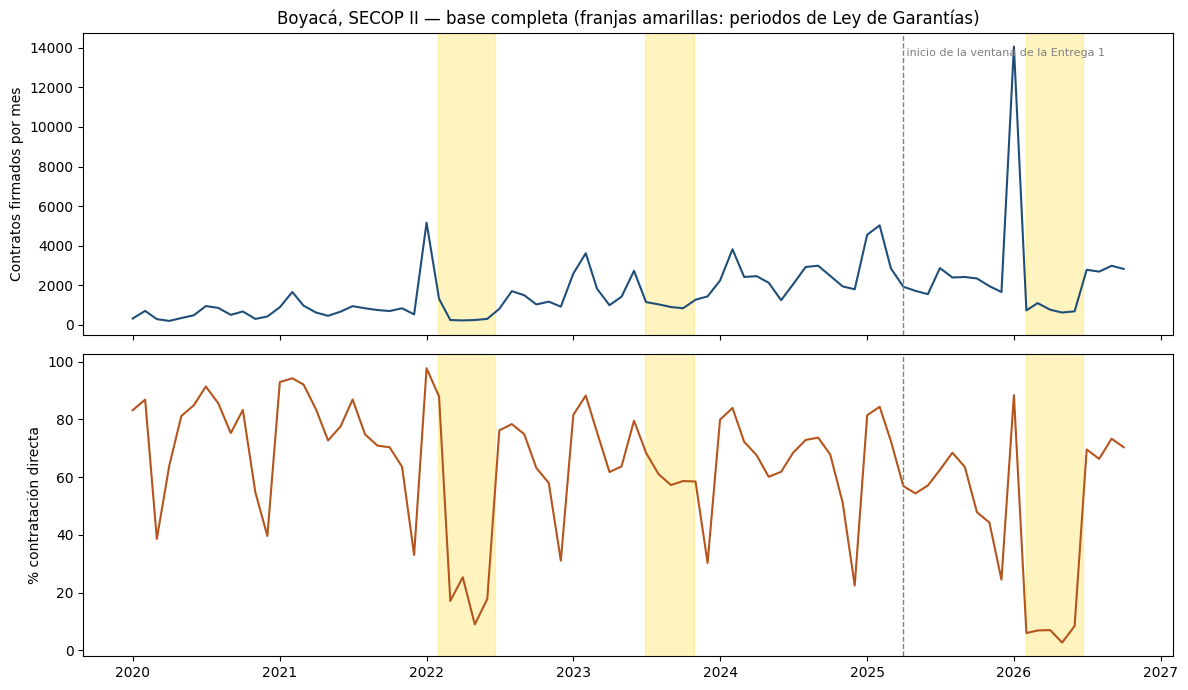

In [9]:
# Fechas
LEY_GARANTIAS = [
    ("Presidencial 2022", "2022-01-29", "2022-06-19"),
    ("Regionales 2023",   "2023-06-29", "2023-10-29"),
    ("Presidencial 2026", "2026-01-31", "2026-06-21"),
]
serie = base.groupby("mes").agg(n=("id_contrato", "size"), directa=("directa", "mean"))
serie.index = serie.index.to_timestamp()
serie = serie[serie.index >= "2020-01-01"]

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(serie.index, serie["n"], color="#1f4e79"); ax[0].set_ylabel("Contratos firmados por mes")
ax[1].plot(serie.index, serie["directa"] * 100, color="#b5541c"); ax[1].set_ylabel("% contratación directa")
e1_ini = pd.Timestamp("2025-04-01")
for a in ax:
    a.axvline(e1_ini, color="gray", ls="--", lw=1)
    for nom, i, f in LEY_GARANTIAS: a.axvspan(pd.Timestamp(i), pd.Timestamp(f), color="gold", alpha=.25)
ax[0].text(e1_ini, ax[0].get_ylim()[1]*0.92, " inicio de la ventana de la Entrega 1", fontsize=8, color="gray")
ax[0].set_title("Boyacá, SECOP II — base completa (franjas amarillas: periodos de Ley de Garantías)")
plt.tight_layout(); plt.show()

In [10]:
# Enero de cada año: ¿el pico de enero-2026 es único o se repite? (2026 va solo hasta octubre, por eso se agrega la razón enero/mes típico)
enero = base[base["fecha_firma"].dt.month == 1].groupby("anio").agg(n=("id_contrato", "size"), directa=("directa", "mean"))
tot_anio = base.groupby("anio").size().rename("total_año")
enero = enero.join(tot_anio); enero["% del año en enero"] = (enero["n"] / enero["total_año"] * 100).round(1)
enero["% directa"] = (enero["directa"] * 100).round(1)
mensual = base.groupby(["anio", "mes"]).size().reset_index(name="n")
mensual["m"] = mensual["mes"].dt.month
tipico = mensual[(mensual["m"] >= 2) & (mensual["m"] <= 10)].groupby("anio")["n"].mean()   # feb-oct: 2026 llega hasta octubre
enero["enero / mes típico (feb-oct)"] = (enero["n"] / tipico).round(1)
enero[["n", "total_año", "% del año en enero", "enero / mes típico (feb-oct)", "% directa"]]

,n,total_año,% del año en enero,enero / mes típico (feb-oct),% directa
anio,,,,,
2018,97,1199,8.1,1.0,79.4
2019,114,1027,11.1,1.5,36.8
2020,321,6059,5.3,0.6,83.2
2021,891,9866,9.0,1.1,92.9
2022,5161,14632,35.3,6.3,97.7
2023,2590,19816,13.1,1.6,81.5
2024,2239,28505,7.9,0.9,79.9
2025,4554,31270,14.6,1.8,81.4
2026,14062,29250,48.1,8.3,88.4


In [11]:
# Directa antes / durante / después de cada franja (comparación preliminar, sin controlar por entidad ni tipo)
filas = []
for nom, i, f in LEY_GARANTIAS:
    i, f = pd.Timestamp(i), pd.Timestamp(f); dur = (f - i).days
    ant = base[(base["fecha_firma"] >= i - pd.Timedelta(days=dur)) & (base["fecha_firma"] < i)]
    en  = base[(base["fecha_firma"] >= i) & (base["fecha_firma"] <= f)]
    des = base[(base["fecha_firma"] > f) & (base["fecha_firma"] <= f + pd.Timedelta(days=dur))]
    for etapa, d in [("antes", ant), ("durante", en), ("después", des)]:
        filas.append((nom, etapa, len(d), round(d["directa"].mean() * 100, 1) if len(d) else np.nan))
pd.DataFrame(filas, columns=["periodo", "etapa", "contratos", "% directa"]).pivot(index="periodo", columns="etapa", values=["contratos", "% directa"])

contratos                  % directa                
etapa                 antes  después durante     antes después durante
periodo                                                               
Presidencial 2022    7557.0   5436.0  2348.0      85.3    72.8    59.8
Presidencial 2026   21215.0  11526.0  3809.0      73.7    68.9     6.4
Regionales 2023      6980.0   8554.0  4041.0      72.9    70.0    62.6

## 6. Hallazgos de esta parte

**Descarga**
- Se bajaron **143.946** contratos de Boyacá (2017-06 → 2026-10-31), 96 columnas + `:id`. El conteo de la fuente y las filas descargadas coinciden (sección 3).
- Base analítica tras el embudo: **141.742** contratos (−1.311 sin fecha de firma, −887 con valor $0, −6 con valor ≥ 10¹¹). Es 3,5 veces la base de la Entrega 1 (40.351).
- Del total, 98.289 son contratación directa estricta (69%), más 3.500 "directa (con ofertas)".

**Frente a la Entrega 1**
- De los 49.793 `id_contrato` únicos de la E1, 41.504 siguen en la fuente. Los 8.289 que ya no están son sobre todo **Borrador (4.660) y Cancelado (3.230)**: SECOP depuró procesos que nunca se firmaron, así que no afecta la base analítica.
- Entre los contratos que siguen, el valor cambió en 7,7%, los días adicionados en 9,5% y el estado en 19,7% (esperable: contratos que avanzaron). La fecha de firma solo en 0,2%.
- La fuente trae 10 columnas ambientales nuevas; la E1 ya había comprobado que son casi constantes.

**Ley de Garantías sin el corte**
- **El pico de enero NO es único de 2026.** Enero de 2022 tuvo 5.161 firmas (35% del año; 6,3 veces un mes típico) con 97,7% por contratación directa, el mismo patrón de enero 2026 (14.062 firmas; 8,3 veces; 88,4% directa), justo antes de las elecciones presidenciales. En los demás años enero es 0,6–1,8 veces un mes típico.
- Con las regionales de 2023 no aparece pico (enero 2023: 1,6 veces).
- Contratación directa antes / durante / después: Presidencial 2026 **73,7% → 6,4% → 68,9%**; Presidencial 2022 85,3% → 59,8% → 72,8%; Regionales 2023 72,9% → 62,6% → 70,0%. En 2026 la caída es muy marcada; en 2022 y 2023 es moderada. Esto es **preliminar**: sin controlar por entidad, tipo ni excepciones legales (la sección 17 lo retoma).

## 7. Eventos de los contratos: Adiciones y Suspensiones (base completa)
Respuesta a la segunda recomendación del profesor: los contratos recientes no han tenido tiempo de modificarse, así que se modela el **tiempo hasta la primera modificación**, con censura en la fecha de corte, en vez de una probabilidad simple.

Fuentes (datos.gov.co): `cb9c-h8sn` (Adiciones: bitácora de modificaciones) y `u99c-7mfm` (Suspensiones). Se descargan los eventos de los 141.742 contratos de la base analítica, en lotes de 200 `id_contrato`, y se guardan en `Datos/eventos/` (reanudable).

In [12]:
import concurrent.futures as cf
EV = os.path.join(AQUI, "Datos", "eventos"); os.makedirs(EV, exist_ok=True)
ids = base["id_contrato"].dropna().unique().tolist()
LOTE, HILOS, LOTES_POR_PARTE = 200, 4, 50
lotes = [ids[i:i + LOTE] for i in range(0, len(ids), LOTE)]
print(f"{len(ids):,} contratos -> {len(lotes)} lotes por dataset")

def pedir_lote(ds, cols, lote):
    lista = ",".join(f"'{x}'" for x in lote)
    url = f"https://www.datos.gov.co/resource/{ds}.json?" + urllib.parse.urlencode({"$select": cols, "$where": f"id_contrato in ({lista})", "$limit": 50000}, safe="$(),'")
    for k in range(6):
        try:
            with urllib.request.urlopen(url, timeout=120) as r: return json.load(r)
        except Exception as e:
            if k == 5: raise
            time.sleep(3 * (k + 1))

def descargar_eventos(ds, cols, nombre):
    total_fallos = 0
    for p in range(0, len(lotes), LOTES_POR_PARTE):
        ruta = os.path.join(EV, f"{nombre}_parte_{p // LOTES_POR_PARTE:03d}.csv.gz")
        if os.path.exists(ruta): continue
        filas, fallos = [], 0
        with cf.ThreadPoolExecutor(HILOS) as ex:
            futs = [ex.submit(pedir_lote, ds, cols, l) for l in lotes[p:p + LOTES_POR_PARTE]]
            for f in futs:
                try: filas.extend(f.result())
                except Exception as e: fallos += 1
        if fallos:   # no se guarda la parte: se reintenta en la siguiente ejecucion
            log(f"  {nombre} parte {p // LOTES_POR_PARTE}: {fallos} lotes fallidos, NO se guarda"); total_fallos += fallos; continue
        pd.DataFrame(filas, columns=cols.split(",")).to_csv(ruta, index=False, compression="gzip")
        log(f"  {nombre} parte {p // LOTES_POR_PARTE + 1}/{-(-len(lotes) // LOTES_POR_PARTE)}: {len(filas):,} eventos")
    return total_fallos

f1 = descargar_eventos("cb9c-h8sn", "id_contrato,tipo,fecharegistro", "adiciones")
f2 = descargar_eventos("u99c-7mfm", "id_contrato,tipo,fecha_de_creacion", "suspensiones")
print("Partes con fallos (si > 0, volver a ejecutar esta celda):", f1, f2)

141,742 contratos -> 709 lotes por dataset
Partes con fallos (si > 0, volver a ejecutar esta celda): 0 0


In [13]:
ad = pd.concat([pd.read_csv(os.path.join(EV, f), dtype=str) for f in sorted(os.listdir(EV)) if f.startswith("adiciones")], ignore_index=True)
su = pd.concat([pd.read_csv(os.path.join(EV, f), dtype=str) for f in sorted(os.listdir(EV)) if f.startswith("suspensiones")], ignore_index=True)
ad["fecha_ev"] = pd.to_datetime(ad["fecharegistro"], errors="coerce");  ad["fuente"] = "adiciones"
su["fecha_ev"] = pd.to_datetime(su["fecha_de_creacion"], errors="coerce"); su["fuente"] = "suspensiones"
print(f"Eventos de Adiciones: {len(ad):,} | de Suspensiones: {len(su):,}")
print("\nTipos en Adiciones:\n", ad["tipo"].value_counts().to_string())
print("\nTipos en Suspensiones:\n", su["tipo"].value_counts().to_string())

Eventos de Adiciones: 263,601 | de Suspensiones: 47,232

Tipos en Adiciones:
 tipo
No definido             92634
Modificacion General    87965
Conclusion              50756
Adicion en el valor     17280
Reactivación             6984
Suspensión               6502
Cesion                   1480

Tipos en Suspensiones:
 tipo
Reanudacion    23997
Suspension     23235


**Definición del evento.** *Primera modificación* = primer evento de tipo Adición en el valor, Modificación general, Suspensión o Cesión (ambas fuentes). Se excluyen *Conclusión* (es el cierre normal del contrato), *Reactivación/Reanudación* (siguen a una suspensión que ya cuenta) y *No definido* (ambiguo). Como variantes: solo **adición en el valor** y solo **suspensión**.
La adición de plazo (`dias_adicionados`) no tiene fecha en la base, por eso no puede entrar como evento con tiempo.

In [14]:
def norm(t): return (str(t).lower().replace("ó", "o").replace("é", "e").strip())
ev = pd.concat([ad[["id_contrato", "tipo", "fecha_ev", "fuente"]], su[["id_contrato", "tipo", "fecha_ev", "fuente"]]], ignore_index=True)
ev["t"] = ev["tipo"].map(norm)
CLASE = {"adicion en el valor": "valor", "modificacion general": "general", "cesion": "cesion", "suspension": "suspension"}
ev["clase"] = ev["t"].map(CLASE)
ev = ev[ev["clase"].notna() & ev["fecha_ev"].notna()]

# fecha del primer evento por contrato y por definicion
def primero(mask): return ev[mask].groupby("id_contrato")["fecha_ev"].min()
b = base.drop_duplicates("id_contrato").set_index("id_contrato").copy()
b["f_cualquiera"] = primero(ev["clase"].notna())
b["f_valor"] = primero(ev["clase"].eq("valor"))
b["f_suspension"] = primero(ev["clase"].eq("suspension"))

CORTE = max(ad["fecha_ev"].max(), su["fecha_ev"].max())
print("Fecha de corte del seguimiento (último evento observado):", CORTE.date())
for c in ["f_cualquiera", "f_valor", "f_suspension"]:
    antes = (b[c] < b["fecha_firma"]).sum()
    print(f"{c}: {b[c].notna().sum():,} contratos con evento ({b[c].notna().mean():.1%}); eventos ANTES de la firma: {antes:,}")

Fecha de corte del seguimiento (último evento observado): 2026-10-31
f_cualquiera: 62,806 contratos con evento (44.3%); eventos ANTES de la firma: 13
f_valor: 15,116 contratos con evento (10.7%); eventos ANTES de la firma: 0
f_suspension: 4,606 contratos con evento (3.2%); eventos ANTES de la firma: 13


In [15]:
# Cobertura por anio de firma: ¿la bitacora de eventos cubre bien los anios antiguos? (si no, hay sesgo)
b["anio"] = b["fecha_firma"].dt.year
cob = b.groupby("anio").agg(contratos=("valor", "size"),
                            con_evento=("f_cualquiera", lambda x: x.notna().mean() * 100),
                            con_valor=("f_valor", lambda x: x.notna().mean() * 100),
                            con_suspension=("f_suspension", lambda x: x.notna().mean() * 100)).round(1)
cob

,contratos,con_evento,con_valor,con_suspension
anio,,,,
2017,118,44.1,6.8,0.0
2018,1199,51.0,31.5,0.4
2019,1027,50.0,32.9,0.5
2020,6059,67.6,17.4,2.0
2021,9866,59.7,17.1,3.6
2022,14632,55.7,12.4,4.1
2023,19816,43.8,12.8,3.0
2024,28505,35.2,8.0,2.9
2025,31270,43.9,9.2,4.0


> **Lectura de la cobertura.** Si el porcentaje de contratos con evento cae mucho en los años antiguos, la bitácora no está completa para ellos (SECOP II registra los eventos desde cierto momento) y comparar años sin cuidado sesgaría el resultado. Se decide con esta tabla desde qué año de firma se modela.

In [16]:
# Tiempo de seguimiento y censura (en dias desde la firma)
def armar(fcol):
    d = b.copy()
    ev_t = (d[fcol] - d["fecha_firma"]).dt.days
    d["evento"] = (d[fcol].notna() & (ev_t >= 0)).astype(int)
    d["tiempo"] = np.where(d["evento"] == 1, ev_t, (CORTE - d["fecha_firma"]).dt.days)
    d = d[d["tiempo"] >= 0].copy(); d["tiempo"] = d["tiempo"].clip(lower=0.5)
    return d
S = {k: armar(c) for k, c in [("cualquiera", "f_cualquiera"), ("valor", "f_valor"), ("suspension", "f_suspension")]}
for k, d in S.items(): print(f"{k:11s} n={len(d):,}  eventos={d['evento'].sum():,} ({d['evento'].mean():.1%})  censurados={(1-d['evento']).sum():,}  mediana de seguimiento={d['tiempo'].median():.0f} dias")

cualquiera  n=141,733  eventos=62,793 (44.3%)  censurados=78,940  mediana de seguimiento=243 dias
valor       n=141,733  eventos=15,116 (10.7%)  censurados=126,617  mediana de seguimiento=675 dias
suspension  n=141,733  eventos=4,593 (3.2%)  censurados=137,140  mediana de seguimiento=781 dias


## 8. Kaplan–Meier: probabilidad de NO haber sido modificado a lo largo del tiempo

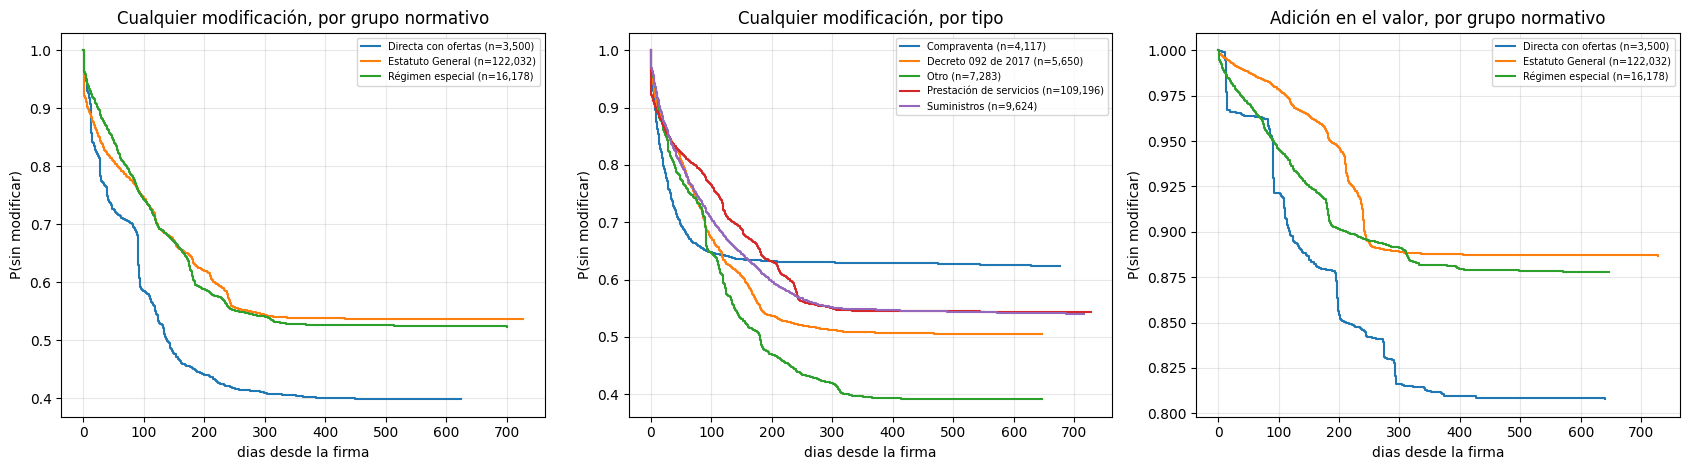

In [17]:
from statsmodels.duration.survfunc import SurvfuncRight
def grupo(m):
    m = str(m).lower()
    if "régimen especial" in m: return "Régimen especial"
    if "directa (con ofertas)" in m: return "Directa con ofertas"
    if "enajenaci" in m: return "Enajenación"
    return "Estatuto General"
b["grupo_normativo"] = b["modalidad_de_contratacion"].map(grupo)
for k in S: S[k]["grupo_normativo"] = S[k].index.map(b["grupo_normativo"])

def km_plot(d, por, titulo, ax, minimo=500, horizonte=730):
    for nombre, g in d.groupby(por):
        if len(g) < minimo: continue
        sf = SurvfuncRight(g["tiempo"], g["evento"])
        x = np.r_[0, sf.surv_times]; y = np.r_[1, sf.surv_prob]
        m = x <= horizonte
        ax.step(x[m], y[m], where="post", label=f"{nombre} (n={len(g):,})")
    ax.set_title(titulo); ax.set_xlabel("dias desde la firma"); ax.set_ylabel("P(sin modificar)"); ax.legend(fontsize=7); ax.grid(alpha=.3)

top_tipos = b["tipo_de_contrato"].value_counts().head(5).index
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
km_plot(S["cualquiera"], "grupo_normativo", "Cualquier modificación, por grupo normativo", ax[0])
km_plot(S["cualquiera"][S["cualquiera"]["tipo_de_contrato"].isin(top_tipos)], "tipo_de_contrato", "Cualquier modificación, por tipo", ax[1])
km_plot(S["valor"], "grupo_normativo", "Adición en el valor, por grupo normativo", ax[2])
plt.tight_layout(); plt.show()

In [18]:
# Probabilidad acumulada de modificación a 90, 180 y 365 dias (Kaplan-Meier), por grupo normativo
def tabla_km(d, por):
    filas = []
    for nombre, g in d.groupby(por):
        if len(g) < 500: continue
        sf = SurvfuncRight(g["tiempo"], g["evento"])
        f = lambda t: (1 - float(np.interp(t, np.r_[0, sf.surv_times], np.r_[1, sf.surv_prob]))) * 100
        filas.append((nombre, len(g), int(g["evento"].sum()), round(f(90), 1), round(f(180), 1), round(f(365), 1)))
    return pd.DataFrame(filas, columns=[por, "n", "eventos", "% a 90 d", "% a 180 d", "% a 365 d"]).set_index(por)
print("Cualquier modificación"); display(tabla_km(S["cualquiera"], "grupo_normativo"))
print("Adición en el valor");   display(tabla_km(S["valor"], "grupo_normativo"))
print("Cualquier modificación, por tipo"); display(tabla_km(S["cualquiera"][S["cualquiera"]["tipo_de_contrato"].isin(top_tipos)], "tipo_de_contrato"))

Cualquier modificación


,n,eventos,% a 90 d,% a 180 d,% a 365 d
grupo_normativo,,,,,
Directa con ofertas,3500,2076,33.3,54.7,59.8
Estatuto General,122032,53454,24.0,36.1,46.2
Régimen especial,16178,7251,24.1,38.9,47.3


Adición en el valor


,n,eventos,% a 90 d,% a 180 d,% a 365 d
grupo_normativo,,,,,
Directa con ofertas,3500,637,6.0,12.1,18.9
Estatuto General,122032,12676,1.9,4.5,11.2
Régimen especial,16178,1803,4.9,8.7,11.8


Cualquier modificación, por tipo


,n,eventos,% a 90 d,% a 180 d,% a 365 d
tipo_de_contrato,,,,,
Compraventa,4117,1515,34.8,36.7,37.1
Decreto 092 de 2017,5650,2680,30.6,44.7,49.2
Otro,7283,4281,30.9,50.3,60.5
Prestación de servicios,109196,46891,22.2,34.9,45.5
Suministros,9624,4194,27.5,38.4,45.2


## 9. Modelo de Cox (riesgos proporcionales) para el tiempo hasta la primera modificación
Predictores interpretables (regla de ≤15): log(valor), duración planeada, año de firma, grupo normativo y tipo de contrato (5 principales + "Otro"). El *hazard ratio* (HR) de una variable es cuánto multiplica el riesgo instantáneo de modificación; HR > 1 = se modifica más rápido. Es una primera versión: aún sin indicadores de riesgo OCP ni variables de entidad.

In [19]:
from statsmodels.duration.hazard_regression import PHReg
def preparar_cox(d, anio_min=None, dur_original=False):
    d = d[d["grupo_normativo"] != "Enajenación"].copy()   # 23 contratos: coeficiente inestable
    d["lv"] = np.log(d["valor"])
    ini = pd.to_datetime(d["fecha_de_inicio_del_contrato"], errors="coerce"); fin = pd.to_datetime(d["fecha_de_fin_del_contrato"], errors="coerce")
    d["dur"] = (fin - ini).dt.days
    d.loc[(d["dur"] < 1) | (d["dur"] > 3650), "dur"] = np.nan
    if dur_original:   # la fecha de fin actual puede incluir prorrogas: se resta lo adicionado
        d["dur"] = d["dur"] - pd.to_numeric(d["dias_adicionados"], errors="coerce").fillna(0)
        d.loc[d["dur"] < 1, "dur"] = np.nan
    d["ldur"] = np.log(d["dur"])
    d["tipo_c"] = np.where(d["tipo_de_contrato"].isin(top_tipos), d["tipo_de_contrato"], "Otro")
    d["anio_c"] = d["fecha_firma"].dt.year - 2022   # centrado para que el HR sea por año
    if anio_min: d = d[d["fecha_firma"].dt.year >= anio_min]
    ref_t = d["tipo_c"].value_counts().index[0]
    X = pd.concat([d[["lv", "ldur", "anio_c"]],
                   pd.get_dummies(d["grupo_normativo"], prefix="g").drop(columns="g_Estatuto General", errors="ignore"),
                   pd.get_dummies(d["tipo_c"], prefix="t").drop(columns=f"t_{ref_t}")], axis=1).astype(float)
    ok = X.notna().all(axis=1)
    return d[ok], X[ok], ref_t

def ajustar_cox(clave, anio_min=None, dur_original=False):
    d, X, ref = preparar_cox(S[clave], anio_min, dur_original)
    m = PHReg(d["tiempo"].values, X.values, status=d["evento"].values, ties="breslow").fit()
    t = pd.DataFrame({"HR": np.exp(m.params), "IC95 inf": np.exp(m.params - 1.96 * m.bse), "IC95 sup": np.exp(m.params + 1.96 * m.bse), "p": m.pvalues}, index=X.columns).round(3)
    print(f"Cox '{clave}' | n={len(d):,} | eventos={int(d['evento'].sum()):,} | referencia de tipo: {ref} | referencia de grupo: Estatuto General")
    return m, t, d, X

m_cualq, t_cualq, d_cualq, X_cualq = ajustar_cox("cualquiera")
t_cualq

Cox 'cualquiera' | n=139,188 | eventos=62,624 | referencia de tipo: Prestación de servicios | referencia de grupo: Estatuto General


,HR,IC95 inf,IC95 sup,p
lv,1.330,1.321,1.339,0.000
ldur,1.319,1.306,1.333,0.000
anio_c,0.912,0.908,0.916,0.000
g_Directa con ofertas,0.961,0.913,1.011,0.127
g_Régimen especial,0.746,0.722,0.770,0.000
t_Compraventa,1.335,1.264,1.411,0.000
t_Decreto 092 de 2017,1.228,1.169,1.291,0.000
t_Otro,0.911,0.882,0.940,0.000
t_Suministros,1.054,1.020,1.089,0.002


In [20]:
# Concordancia (C-index) fuera de tiempo: entrenar con firmados antes de 2025-01-01 y evaluar en los firmados despues.
# (Aun con censura, el C-index mide si el modelo ordena bien quien se modifica antes.)
def cindex(tiempo, evento, riesgo):
    rng = np.random.default_rng(0); n = len(tiempo)
    idx = rng.choice(n, size=min(n, 8000), replace=False)    # submuestra: el calculo exacto es O(n^2)
    t, e, r = tiempo[idx], evento[idx], riesgo[idx]
    conc = tot = 0
    for i in np.where(e == 1)[0]:
        comparables = t > t[i]
        tot += comparables.sum(); conc += (r[i] > r[comparables]).sum() + 0.5 * (r[i] == r[comparables]).sum()
    return conc / tot

def cindex_fuera_de_tiempo(dur_original=False):
    d, X, _ = preparar_cox(S["cualquiera"], dur_original=dur_original)
    tr = d["fecha_firma"] < "2025-01-01"
    mt = PHReg(d.loc[tr, "tiempo"].values, X[tr].values, status=d.loc[tr, "evento"].values, ties="breslow").fit()
    assert np.isfinite(mt.params).all() and np.abs(mt.params).max() < 20, "coeficientes degenerados"
    riesgo = (X[~tr].values * mt.params).sum(axis=1)      # sin matmul (avisos espurios de BLAS en macOS)
    assert np.isfinite(X[~tr].values).all() and np.isfinite(riesgo).all(), "riesgo no finito"
    return tr.sum(), (~tr).sum(), cindex(d.loc[~tr, "tiempo"].values, d.loc[~tr, "evento"].values, riesgo)
for lab, flag in [("duración actual (fecha de fin vigente)", False), ("duración original (fin − días adicionados)", True)]:
    ntr, nte, c = cindex_fuera_de_tiempo(flag)
    print(f"{lab}: entrena {ntr:,} (firmados antes de 2025) | prueba {nte:,} (2025 en adelante) | C-index = {c:.3f}  (0,5 = azar)")

duración actual (fecha de fin vigente): entrena 80,130 (firmados antes de 2025) | prueba 59,058 (2025 en adelante) | C-index = 0.617  (0,5 = azar)


duración original (fin − días adicionados): entrena 80,115 (firmados antes de 2025) | prueba 58,712 (2025 en adelante) | C-index = 0.597  (0,5 = azar)


In [21]:
# Sensibilidad: ¿el HR de la duración depende de usar la fecha de fin vigente (que puede incluir prorrogas)?
_, t_orig, _, _ = ajustar_cox("cualquiera", dur_original=True)
pd.concat([t_cualq.loc[["lv", "ldur", "anio_c"], ["HR"]].rename(columns={"HR": "HR duración actual"}),
           t_orig.loc[["lv", "ldur", "anio_c"], ["HR"]].rename(columns={"HR": "HR duración original"})], axis=1)

Cox 'cualquiera' | n=138,827 | eventos=62,357 | referencia de tipo: Prestación de servicios | referencia de grupo: Estatuto General


,HR duración actual,HR duración original
lv,1.330,1.367
ldur,1.319,1.197
anio_c,0.912,0.911


## 10. Hallazgos de la supervivencia

**Datos de eventos.** 263.601 eventos de Adiciones y 47.232 de Suspensiones para los 141.742 contratos. Evento = primera adición en valor, modificación general, suspensión o cesión. El 44,3% de los contratos tiene al menos uno (62.806); solo el 10,7% tiene adición en valor y el 3,2% suspensión. 92.634 eventos de Adiciones son "No definido" y no se usaron.

**Cobertura.** La bitácora cubre los años antiguos (44–68% de los contratos con algún evento en 2017–2022), así que no hay un quiebre que obligue a recortar el periodo. Los años recientes tienen menos eventos porque no han tenido tiempo de ocurrir (censura), que es justo lo que corrige la supervivencia.

**Kaplan–Meier (probabilidad acumulada de modificación).**
| Grupo | a 90 d | a 180 d | a 365 d |
|---|---|---|---|
| Estatuto General (n=122.032) | 24,0% | 36,1% | 46,2% |
| Régimen especial (n=16.178) | 24,1% | 38,9% | 47,3% |
| Directa con ofertas (n=3.500) | 33,3% | 54,7% | 59,8% |
La adición en valor a 365 días es 11,2% en Estatuto General y 18,9% en "directa con ofertas". Por tipo, "Otro" llega a 60,5% a 365 días.

**Cox (hazard ratios, n=139.188, 62.624 eventos).** Mayor valor (HR 1,33 por unidad de log) y mayor duración se asocian con modificarse antes; régimen especial se modifica más lento que el Estatuto General (HR 0,75); compraventa (1,34) y Decreto 092 (1,23) más rápido que prestación de servicios. Los contratos más recientes se modifican más lento (HR 0,91 por año de firma): requiere explicación antes de interpretarlo, pues puede reflejar cambios en cómo se registra la bitácora y no un comportamiento real.

**Alerta de fuga de información.** La fecha de fin vigente puede incluir prórrogas. Con la duración original (fin − días adicionados) el HR de la duración baja de 1,32 a 1,20 y el C-index de 0,617 a 0,597. **El valor honesto es el segundo.**

**Poder predictivo fuera de tiempo** (entrenar con firmados antes de 2025, probar con 2025 en adelante): C-index **0,60** con la duración original. Es modesto: sirve para ordenar riesgo, no para predecir contratos individuales. Por eso la sección 13 agrega los indicadores de riesgo de OCP.

**Limitaciones**
- Evento definido sobre modificaciones de cualquier tipo; "Modificación general" (37% de las usadas) es genérica.
- El dataset de Adiciones no trae montos ni motivo.
- No controla por entidad y el efecto del año de firma queda sin explicar. Las secciones 13 a 15 rehacen el análisis con la historia de adiciones de cada entidad y con variables limpias.

> **Actualización (16-nov-2026).** La sección 11 comprobó que `valor_del_contrato` es el valor vigente e incluye las adiciones, y que la fecha de fin vigente incluye prórrogas. El Cox de esta sección usó ambas, así que sus *hazard ratios* y su C-index no se deben citar. Se rehízo con variables limpias en la sección 15.

## 11. Control de calidad: el valor del contrato ya incluye las adiciones
Antes de construir los indicadores de riesgo se revisó una sospecha: la sección 3 mostró que `valor_del_contrato` cambió en el 7,7 % de los contratos entre la descarga de la Entrega 1 y la actual. Si ese campo se actualiza cuando hay una adición, usarlo como predictor de la adición es **fuga de información** (el modelo vería el resultado dentro de la variable).

La prueba compara el mismo contrato en las dos descargas y cruza con la bitácora: ¿subió el valor justo en los contratos que registraron una adición en valor después del 20-ago-2026?

In [22]:
import warnings; warnings.filterwarnings("ignore")
v_e1 = pd.to_numeric(e1.drop_duplicates("id_contrato").set_index("id_contrato")["valor_del_contrato"], errors="coerce").rename("valor_e1")
cmp = b.join(v_e1, how="inner")
cmp["subio"] = cmp["valor"] > cmp["valor_e1"] + 0.5
D0 = pd.Timestamp("2026-08-20")                                  # dia siguiente a la ultima firma de la descarga de la Entrega 1
con_adic = ev.loc[ev["clase"].eq("valor") & (ev["fecha_ev"] >= D0), "id_contrato"].unique()
cmp["adicion_posterior"] = cmp.index.isin(con_adic)
print(f"Contratos presentes en las dos descargas: {len(cmp):,}")
display(pd.crosstab(cmp["adicion_posterior"], cmp["subio"], margins=True).rename_axis(index="adición en valor después del 20-ago", columns="el valor subió"))
x = cmp[cmp["adicion_posterior"] & cmp["subio"]]
print(f"Con adición posterior, el valor subió en el {cmp.loc[cmp['adicion_posterior'], 'subio'].mean():.1%} de los contratos (aumento mediano: {(x['valor'] / x['valor_e1'] - 1).median():.1%}).")
print(f"Sin adición posterior, el valor subió en el {cmp.loc[~cmp['adicion_posterior'], 'subio'].mean():.1%}.")

Contratos presentes en las dos descargas: 40,055


el valor subió,False,True,All
adición en valor después del 20-ago,,,
False,36946,1811,38757
True,19,1279,1298
All,36965,3090,40055


Con adición posterior, el valor subió en el 98.5% de los contratos (aumento mediano: 37.5%).
Sin adición posterior, el valor subió en el 4.7%.


> **Resultado.** El valor subió en el 98,5 % de los contratos con adición posterior (aumento mediano de 37,5 %) y solo en el 4,7 % del resto. `valor_del_contrato` es el **valor vigente**, no el inicial.
>
> **Consecuencias.**
> - El Cox de la sección 9 usó `log(valor)` y la fecha de fin vigente: parte de su capacidad de ordenar venía de esta fuga. Se rehace en la sección 15 con variables limpias.
> - Las banderas de umbral no se pueden calcular con el valor vigente: un contrato firmado bajo el tope aparece por encima después de la adición.
> - Hace falta el valor inicial. Está en otro conjunto de datos: el de **procesos** de SECOP II (sección 12).

## 12. Datos del proceso: valor inicial, duración planeada y ofertas recibidas
Fuente: SECOP II – Procesos de Contratación (`p6dx-8zbt`, datos.gov.co). Se cruza con los contratos por `proceso_de_compra` = `id_del_portafolio`. De ahí salen tres variables conocidas **antes de la firma**:
- `precio_base`: presupuesto oficial del proceso. Es el valor que la ley compara contra los topes.
- `duracion` + `unidad_de_duracion`: plazo planeado.
- `respuestas_al_procedimiento`: número de ofertas recibidas.

El precio base es del proceso completo, así que solo se usa como valor inicial del contrato cuando el proceso tiene **un solo contrato**.

In [23]:
RUTA_PROC = os.path.join(AQUI, "Datos", "procesos_boyaca.csv.gz")
COLS_PROC = "id_del_portafolio,id_del_proceso,precio_base,duracion,unidad_de_duracion,fecha_de_publicacion_del,modalidad_de_contratacion,proveedores_invitados,respuestas_al_procedimiento,proveedores_unicos_con,numero_de_lotes,adjudicado,valor_total_adjudicacion"
if not os.path.exists(RUTA_PROC):                                 # descarga unica (~2 min); si el archivo existe no se repite
    partes, off = [], 0
    while True:
        url = "https://www.datos.gov.co/resource/p6dx-8zbt.csv?" + urllib.parse.urlencode(
            {"$select": COLS_PROC + ",:id", "$where": f"departamento_entidad='{DEPTO}'", "$order": ":id", "$limit": 50000, "$offset": off}, safe="$(),':")
        with urllib.request.urlopen(url, timeout=240) as r: d = pd.read_csv(io.BytesIO(r.read()), dtype=str)
        partes.append(d); log(f"procesos: {off + len(d):,}")
        if len(d) < 50000: break
        off += 50000
    pd.concat(partes, ignore_index=True).to_csv(RUTA_PROC, index=False, compression="gzip")
pr = pd.read_csv(RUTA_PROC, dtype=str)
pr["fpub"] = pd.to_datetime(pr["fecha_de_publicacion_del"], errors="coerce")
p1 = pr.sort_values("fpub").drop_duplicates("id_del_portafolio", keep="last").set_index("id_del_portafolio")   # un registro por proceso: la publicacion mas reciente
for c in ["precio_base", "duracion", "respuestas_al_procedimiento"]: p1[c] = pd.to_numeric(p1[c], errors="coerce")

f = b.join(p1[["precio_base", "duracion", "unidad_de_duracion", "respuestas_al_procedimiento"]], on="proceso_de_compra")
f["n_en_proceso"] = f.groupby("proceso_de_compra")["valor"].transform("size")
f["v0"] = np.where((f["n_en_proceso"] == 1) & (f["precio_base"] > 0), f["precio_base"], np.nan)                 # valor inicial
UNIDAD = {"día(s)": 1, "Mes(es)": 30, "Año(s)": 365, "Semana(s)": 7, "Hora(s)": 1 / 24}
f["dur0"] = (f["duracion"] * f["unidad_de_duracion"].map(UNIDAD)).where(lambda s: (s >= 1) & (s <= 3650))       # plazo planeado en dias
f["adic_valor"] = f["f_valor"].notna()
print(f"Procesos de Boyacá descargados: {len(pr):,} ({pr['id_del_portafolio'].nunique():,} portafolios)")
print(f"Contratos con proceso encontrado: {f['precio_base'].notna().mean():.1%} | en proceso de un solo contrato: {(f['n_en_proceso'] == 1).mean():.1%}")
print(f"Con valor inicial utilizable: {f['v0'].notna().sum():,} ({f['v0'].notna().mean():.1%}) | con plazo planeado: {f['dur0'].notna().mean():.1%}")
u = f[f["v0"].notna()].assign(razon=lambda d: d["valor"] / d["v0"])
print("\nValor vigente / precio base, según haya o no adición en valor registrada:")
display(u.groupby("adic_valor")["razon"].describe(percentiles=[.25, .5, .75, .95])[["count", "25%", "50%", "75%", "95%"]].round(3))

Procesos de Boyacá descargados: 254,976 (244,857 portafolios)
Contratos con proceso encontrado: 99.9% | en proceso de un solo contrato: 95.3%
Con valor inicial utilizable: 134,636 (95.0%) | con plazo planeado: 95.5%

Valor vigente / precio base, según haya o no adición en valor registrada:


,count,25%,50%,75%,95%
adic_valor,,,,,
False,119886.0,1.000,1.000,1.000,1.5
True,14750.0,1.143,1.296,1.429,1.5


> **Lectura.** El cruce encuentra el proceso del 99,9 % de los contratos y deja valor inicial para el 95,0 % (134.636). En los contratos **sin** adición la razón valor vigente / precio base es 1,00 en la mediana; en los que **sí** tienen adición es 1,30, y el percentil 95 es 1,50 en ambos grupos: coincide con el límite legal de adición (50 % del valor inicial, Ley 80 de 1993, art. 40). El precio base no se actualiza con las adiciones, así que sirve como valor inicial.
>
> Un 17 % de los contratos sin "adición en valor" en la bitácora tiene hoy un valor mayor que su precio base. Parte de las adiciones puede estar registrada como "Modificación general" o "No definido": el evento usado **subestima** las adiciones reales. Se deja como limitación.

## 13. Indicadores de riesgo de Open Contracting Partnership, como variables
Respuesta a la tercera recomendación del profesor. Referencia: Salazar, C. (2024). *Red flags in public procurement: A guide to using data to detect and mitigate risks*. Open Contracting Partnership (73 indicadores, R001–R073). El detalle del mapeo está en `Anexos/Indicadores_OCP_aplicables.md`.

| Variable | Indicador OCP | Cómo se calcula aquí |
|---|---|---|
| `share_prov`, `prev_prov_ent`, `prov_nuevo` | R040 *High share of buyer's contracts* (proveedor recurrente) | Participación del proveedor en el valor contratado por la entidad en los 12 meses anteriores; número de contratos previos; si es su primer contrato con la entidad |
| `bajo_tope` | R049 *Direct awards below threshold* | Mínima cuantía con presupuesto entre 95 % y 100 % del tope de la entidad |
| `frac` | R011 *Splitting purchases* / R055 *Multiple direct awards* | Mínima cuantía con otro contrato de mínima cuantía de la misma entidad y proveedor en los 90 días anteriores, cada uno bajo el tope y con suma por encima |
| `oferta_unica` | R018 *Single bid received* | Modalidad con competencia que recibió una sola oferta |
| `pct_directa_ent` | R013 *High use of non-competitive methods* | Proporción de contratación directa de la entidad en los 12 meses anteriores |
| `n_segmentos` | R048 *Heterogeneous supplier* | Segmentos UNSPSC distintos en los contratos anteriores del proveedor |
| `salto_grande` | R052 *Small initial purchase followed by much larger purchases* | Valor inicial mayor al doble del contrato anterior con la misma entidad |
| `hist_ent`, `hist_prov` | R064 / R069 (modificaciones y adiciones), como **antecedente** | Tasa de adición en valor de la entidad y del proveedor en contratos anteriores cuyo resultado ya se conoce |

**Adaptaciones propias (hay que declararlas):**
1. R049 y R011 hablan de *adjudicaciones directas* bajo el umbral. En Colombia la contratación directa depende de una causal, no del valor. La modalidad que sí depende del valor es la **mínima cuantía**, y sobre ella se aplican.
2. La guía calcula los indicadores sobre el periodo completo. Aquí cada indicador usa **solo contratos firmados antes** del contrato evaluado, para poder usarlo como predictor sin fuga.
3. El resultado que se quiere anticipar (adición en valor) corresponde a los indicadores R064 y R069 de la etapa de ejecución. La pregunta queda: *¿las señales visibles al firmar anticipan las señales de ejecución?*

### 13.1 El tope de la mínima cuantía
La Ley 1150 de 2007 (art. 2) fija la menor cuantía en 280, 450, 650, 850 o 1.000 salarios mínimos según el presupuesto anual de la entidad; la mínima cuantía es el 10 %: **28, 45, 65, 85 o 100 SMMLV**. Como el presupuesto de la entidad no está en los datos, su nivel se infiere: el menor de los cinco topes que cubre el percentil 95 de sus presupuestos de mínima cuantía.

Mínima cuantía con valor inicial: 18,070 contratos de 196 entidades
Entidades por tope inferido (SMMLV): {28.0: 179, 45.0: 4, 65.0: 3, 85.0: 1, 100.0: 9}
Presupuestos por encima del tope inferido: 0.15%
Justo bajo el tope (95–100 %): 3,672 contratos (20.3% de la mínima cuantía)


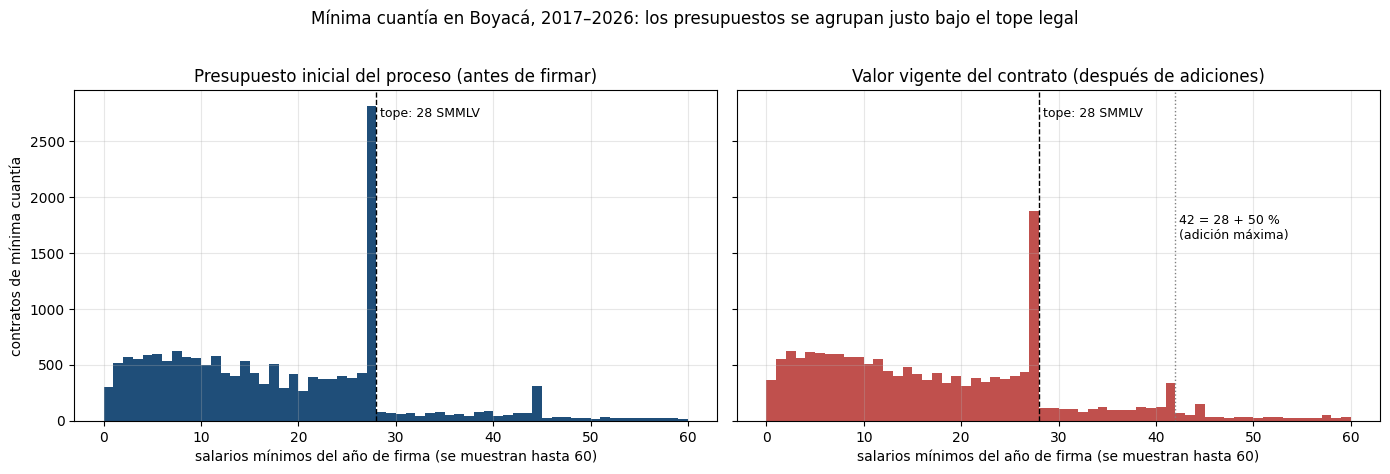

Contratos por tramo de presupuesto (SMMLV): {'(22, 24]': 747, '(24, 26]': 777, '(26, 28]': 3237, '(28, 30]': 146, '(30, 32]': 127}


In [24]:
SMMLV = {2017: 737717, 2018: 781242, 2019: 828116, 2020: 877803, 2021: 908526, 2022: 1000000, 2023: 1160000, 2024: 1300000, 2025: 1423500, 2026: 1750905}
f["sm0"] = f["v0"] / f["anio"].map(SMMLV)                          # valor inicial en salarios minimos del anio de firma
f["sm_act"] = f["valor"] / f["anio"].map(SMMLV)                    # valor vigente en salarios minimos
f["es_mc"] = f["modalidad_de_contratacion"].eq("Mínima cuantía")
TOPES = np.array([28, 45, 65, 85, 100])
def nivel(v):
    k = TOPES[TOPES * 1.01 >= v]; return k[0] if len(k) else 100
p95 = f[f["es_mc"] & f["sm0"].notna()].groupby("nit_entidad")["sm0"].quantile(.95)
f["tope"] = f["nit_entidad"].map(p95.map(nivel))
f["ratio_tope"] = np.where(f["es_mc"], f["sm0"] / f["tope"], np.nan)
f["bajo_tope"] = f["ratio_tope"].between(.95, 1.01).astype(int)   # R049 adaptado

mcd = f[f["es_mc"] & f["sm0"].notna()]
print(f"Mínima cuantía con valor inicial: {len(mcd):,} contratos de {mcd['nit_entidad'].nunique()} entidades")
print("Entidades por tope inferido (SMMLV):", mcd.groupby("nit_entidad")["tope"].first().value_counts().sort_index().astype(int).to_dict())
print(f"Presupuestos por encima del tope inferido: {(mcd['ratio_tope'] > 1.01).mean():.2%}")
print(f"Justo bajo el tope (95–100 %): {mcd['bajo_tope'].sum():,} contratos ({mcd['bajo_tope'].mean():.1%} de la mínima cuantía)")

os.makedirs(os.path.join(AQUI, "Figuras"), exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
bins = np.arange(0, 61, 1)                                       # tramos de 1 SMMLV cerrados a la derecha: (27, 28] incluye el tope exacto
en_rango = lambda s: s[s <= 60] - 1e-6
ax[0].hist(en_rango(mcd["sm0"]), bins=bins, color="#1f4e79")
ax[0].set_title("Presupuesto inicial del proceso (antes de firmar)")
ax[1].hist(en_rango(mcd["sm_act"]), bins=bins, color="#c0504d")
ax[1].set_title("Valor vigente del contrato (después de adiciones)")
for a in ax:
    a.axvline(28, color="k", ls="--", lw=1); a.text(28.4, a.get_ylim()[1] * .92, "tope: 28 SMMLV", fontsize=9)
    a.set_xlabel("salarios mínimos del año de firma (se muestran hasta 60)"); a.grid(alpha=.3)
ax[1].axvline(42, color="gray", ls=":", lw=1); ax[1].text(42.4, ax[1].get_ylim()[1] * .55, "42 = 28 + 50 %\n(adición máxima)", fontsize=9)
ax[0].set_ylabel("contratos de mínima cuantía")
fig.suptitle("Mínima cuantía en Boyacá, 2017–2026: los presupuestos se agrupan justo bajo el tope legal", y=1.02)
plt.tight_layout(); plt.savefig(os.path.join(AQUI, "Figuras", "fig_tope_minima_cuantia.png"), dpi=300, bbox_inches="tight"); plt.show()
t = pd.cut(mcd["sm0"], [22, 24, 26, 28, 30, 32]).value_counts().sort_index()
print("Contratos por tramo de presupuesto (SMMLV):", {str(k): int(v) for k, v in t.items()})

> **Lectura.** Con el presupuesto inicial el agrupamiento es nítido: 3.237 contratos entre 26 y 28 salarios mínimos, frente a 777 en el tramo anterior y 146 en el siguiente. Casi todas las entidades (179 de 196) quedan en el tope de 28 SMMLV y solo el 0,15 % de los presupuestos supera el tope inferido, así que la regla es consistente con la ley.
>
> El panel derecho explica el pico de 41–42 salarios mínimos que aparecía con el valor vigente: 42 = 28 × 1,5. Son contratos presupuestados en el tope que recibieron la adición máxima permitida (50 %).
>
> Agruparse bajo el tope no es irregular por sí mismo: fijar el presupuesto en el máximo de la modalidad es una práctica legal. Es una bandera para revisar, no una acusación.

### 13.2 Construcción de las demás variables (solo con información anterior a la firma)

In [25]:
f["dia"] = (f["fecha_firma"].dt.normalize() - pd.Timestamp("2017-01-01")).dt.days
f["vx"] = f["v0"].fillna(f["valor"])                               # para sumar historia: valor inicial si existe
f["prov"] = f["documento_proveedor"].where(~f["documento_proveedor"].isin(["No Definido", "No definido"]))

def ventana(df, claves, dias, valor="vx", incluir_mismo_dia=False, mask=None):
    """Para cada contrato: numero y suma de `valor` de los OTROS contratos del mismo grupo firmados en los `dias` anteriores."""
    n = pd.Series(0.0, index=df.index); s = pd.Series(0.0, index=df.index)
    d = df if mask is None else df[mask]
    d = d[d[claves].notna().all(axis=1)] if isinstance(claves, list) else d[d[claves].notna()]
    for _, g in d.groupby(claves, sort=False):
        if len(g) < 2: continue
        g = g.sort_values("dia"); t = g["dia"].values; v = g[valor].values; cs = np.r_[0, np.cumsum(v)]
        lo = np.searchsorted(t, t - dias, side="left")
        hi = np.searchsorted(t, t, side="right" if incluir_mismo_dia else "left")
        cnt = hi - lo; sm_ = cs[hi] - cs[lo]
        if incluir_mismo_dia: cnt = cnt - 1; sm_ = sm_ - v
        n.loc[g.index] = cnt; s.loc[g.index] = sm_
    return n, s

# R040: proveedor recurrente (12 meses anteriores)
n_pe, s_pe = ventana(f, ["nit_entidad", "prov"], 365)
n_e, s_e = ventana(f, "nit_entidad", 365)
f["prev_prov_ent"] = n_pe
f["share_prov"] = np.where(s_e > 0, s_pe / s_e, 0.0)
f["prov_nuevo"] = (ventana(f, ["nit_entidad", "prov"], 10**5)[0] == 0).astype(int)
# R013: uso de contratacion directa de la entidad (12 meses anteriores; se exige un minimo de 10 contratos)
f["uno_dir"] = f["directa"].astype(float)
_, s_dir = ventana(f, "nit_entidad", 365, valor="uno_dir")
f["pct_directa_ent"] = np.where(n_e >= 10, s_dir / n_e.where(n_e > 0, 1), np.nan)
# R011 / R055: fraccionamiento en minima cuantia
mc = f["es_mc"] & f["sm0"].notna()
n90, s90 = ventana(f, ["nit_entidad", "prov"], 90, valor="sm0", incluir_mismo_dia=True, mask=mc)
f["frac"] = (mc & (n90 >= 1) & (f["sm0"] <= f["tope"] * 1.01) & (s90 + f["sm0"] > f["tope"] * 1.01)).astype(int)
# R018: oferta unica en modalidades con competencia
COMPET = ~f["modalidad_de_contratacion"].isin(["Contratación directa", "Contratación régimen especial", "No Definido"])
f["competitiva"] = COMPET.astype(int)
f["oferta_unica"] = (COMPET & (f["respuestas_al_procedimiento"] == 1)).astype(int)
# R048: proveedor heterogeneo (segmentos UNSPSC distintos en sus contratos de dias anteriores)
f["seg"] = f["codigo_de_categoria_principal"].str.extract(r"(\d{2})")[0]
het = pd.Series(0, index=f.index)
for _, g in f[f["prov"].notna()].sort_values("dia").groupby("prov", sort=False):
    if len(g) < 2: continue
    vistos, out, pend, dia_ant = set(), [], [], None
    for d_, s_ in zip(g["dia"].values, g["seg"].values):
        if d_ != dia_ant: vistos.update(pend); pend = []; dia_ant = d_
        out.append(len(vistos)); pend.append(s_)
    het.loc[g.index] = out
f["n_segmentos"] = het
# R052: salto de valor frente al contrato anterior con la misma entidad
gp = f[f["prov"].notna() & f["v0"].notna()].sort_values("dia").groupby(["nit_entidad", "prov"], sort=False)["v0"]
f["salto_grande"] = ((f["v0"] / gp.shift(1).reindex(f.index)) > 2).astype(int)
f["enero"] = (f["fecha_firma"].dt.month == 1).astype(int)

# R064 / R069 como antecedente: tasa historica de adicion, solo con resultados ya observados.
# Para un contrato firmado en t se usan los firmados antes de t-365: su ventana de 365 dias ya se cerro.
H = 365
de = (f["f_valor"] - f["fecha_firma"]).dt.days
f["y365"] = ((de >= 0) & (de <= H)).astype(float)                 # adicion en valor dentro de los 365 dias siguientes a la firma
def historia(df, claves):
    k = pd.Series(0.0, index=df.index); n = pd.Series(0.0, index=df.index)
    d = df[df[claves].notna()]
    for _, g in d.groupby(claves, sort=False):
        if len(g) < 2: continue
        g = g.sort_values("dia"); t = g["dia"].values; cs = np.r_[0, np.cumsum(g["y365"].values)]
        hi = np.searchsorted(t, t - H, side="left")
        k.loc[g.index] = cs[hi]; n.loc[g.index] = hi
    return k, n
k_e, n_he = historia(f, "nit_entidad"); k_p, n_hp = historia(f, "prov")
P0 = 0.10                                                          # tasa de referencia para suavizar entidades y proveedores con poca historia
f["hist_ent"] = (k_e + 20 * P0) / (n_he + 20)
f["hist_prov"] = (k_p + 5 * P0) / (n_hp + 5)

print("Prevalencia de cada bandera (toda la base):")
for c, lab in [("bajo_tope", "R049 justo bajo el tope"), ("frac", "R011/R055 fraccionamiento"), ("oferta_unica", "R018 oferta única"),
               ("prov_nuevo", "proveedor nuevo en la entidad"), ("salto_grande", "R052 salto de valor > 2x")]:
    print(f"  {lab:32s} {f[c].sum():7,d}  {f[c].mean():6.1%}")
print(f"  dentro de mínima cuantía: bajo el tope {mcd['bajo_tope'].mean():.1%} | fraccionamiento {f.loc[mcd.index, 'frac'].mean():.1%} | oferta única {f.loc[mcd.index, 'oferta_unica'].mean():.1%}")
display(f[["share_prov", "prev_prov_ent", "pct_directa_ent", "n_segmentos", "hist_ent", "hist_prov"]].describe(percentiles=[.5, .9, .99]).round(3))

Prevalencia de cada bandera (toda la base):
  R049 justo bajo el tope            3,672    2.6%
  R011/R055 fraccionamiento          3,378    2.4%
  R018 oferta única                 19,754   13.9%
  proveedor nuevo en la entidad     52,640   37.1%
  R052 salto de valor > 2x          15,688   11.1%
  dentro de mínima cuantía: bajo el tope 20.3% | fraccionamiento 18.7% | oferta única 52.1%


,share_prov,prev_prov_ent,pct_directa_ent,n_segmentos,hist_ent,hist_prov
count,141742.000,141742.000,137069.000,141742.000,141742.000,141742.000
mean,0.010,1.073,0.706,1.821,0.130,0.113
std,0.062,2.010,0.260,3.536,0.120,0.073
min,0.000,0.000,0.000,0.000,0.003,0.005
50%,0.000,1.000,0.783,1.000,0.095,0.100
90%,0.008,2.000,0.940,4.000,0.344,0.206
99%,0.230,10.000,0.973,18.000,0.476,0.438
max,1.000,54.000,1.000,40.000,0.615,0.750


### 13.3 ¿Se asocia cada bandera con la adición en valor?
Prueba chi-cuadrado sobre los contratos con al menos 365 días de seguimiento (firmados hasta el 31-oct-2025). Resultado: adición en valor dentro de los 365 días siguientes a la firma. Con casi 100 mil contratos casi cualquier diferencia da p < 0,001, así que se reporta la **diferencia en puntos porcentuales** y la V de Cramér (tamaño del efecto).

,n,n con bandera,% adición con bandera,% adición sin bandera,diferencia (p.p.),chi2,p,V de Cramér
comparación,,,,,,,,
Mínima cuantía: justo bajo el tope (R049),13815,2839,18.3,13.1,5.1,48.4,"< 0,001",0.059
Mínima cuantía: fraccionamiento (R011/R055),13815,2338,14.8,14.1,0.7,0.8,"0,38",0.007
Modalidades con competencia: oferta única (R018),24260,14445,15.8,15.8,-0.0,0.0,"0,98",0.000
Todos: proveedor con > 10 % del valor de la entidad (R040),108737,2311,22.0,11.4,10.6,246.1,"< 0,001",0.048
Todos: salto de valor > 2x (R052),108737,11790,21.7,10.4,11.3,1303.1,"< 0,001",0.109
Todos: proveedor nuevo en la entidad,108737,44630,9.0,13.5,-4.5,514.0,"< 0,001",0.069
Todos: firmado en enero,108737,15967,14.6,11.1,3.5,161.5,"< 0,001",0.039


R054 — mínima cuantía que hoy supera el tope: 1,131 de 18,070 (6.3%)
   entre las presupuestadas justo bajo el tope: 23.0% | en el resto: 2.0%
   razón valor vigente / inicial en esos contratos: mediana 1.47


,tasa histórica de la entidad,mediana,contratos,entidades,con adición a 365 días (KM)
grupo,,,,,
Historia baja,"0,3 % a 5,7 %","2,7 %",47309,88,"1,9 %"
Historia media,"5,7 % a 12,5 %","9,5 %",47665,358,"10,0 %"
Historia alta,"12,5 % a 61,5 %","27,5 %",46759,124,"22,2 %"


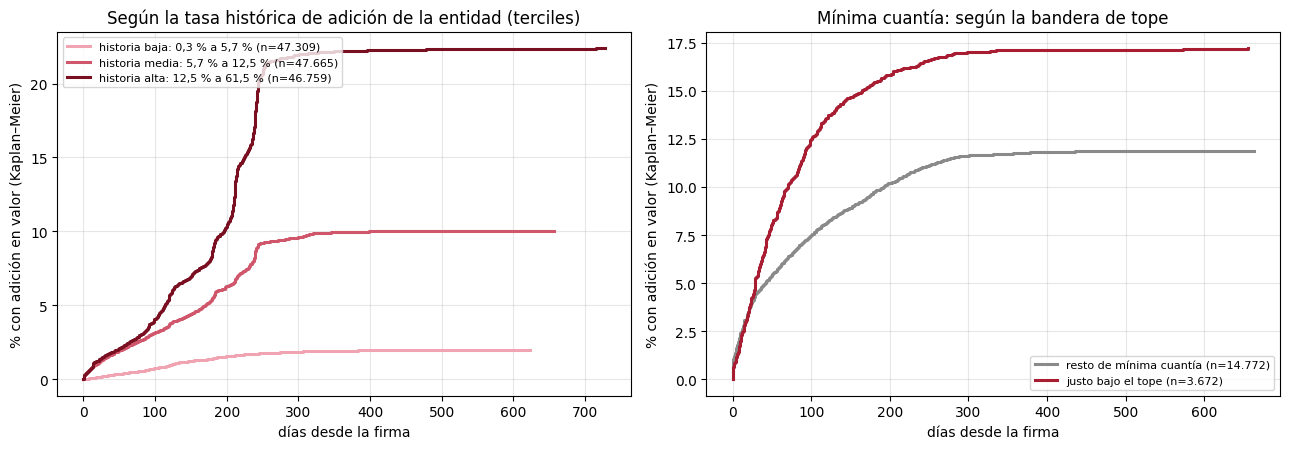

In [26]:
from scipy import stats
seg0 = f[f["fecha_firma"] <= CORTE - pd.Timedelta(days=H)].copy()
seg0["share10"] = (seg0["share_prov"] > .10).astype(int)
def chi(mask, flag, lab):
    d = seg0[mask]; c2, p, _, _ = stats.chi2_contingency(pd.crosstab(d[flag] == 1, d["y365"]))
    a, s = d.loc[d[flag] == 1, "y365"].mean() * 100, d.loc[d[flag] != 1, "y365"].mean() * 100
    return {"comparación": lab, "n": len(d), "n con bandera": int((d[flag] == 1).sum()), "% adición con bandera": round(a, 1), "% adición sin bandera": round(s, 1),
            "diferencia (p.p.)": round(a - s, 1), "chi2": round(c2, 1), "p": ("< 0,001" if p < .001 else f"{p:.2f}".replace(".", ",")), "V de Cramér": round(np.sqrt(c2 / len(d)), 3)}
todos = pd.Series(True, index=seg0.index)
tab_chi = pd.DataFrame([chi(seg0["es_mc"], "bajo_tope", "Mínima cuantía: justo bajo el tope (R049)"),
                        chi(seg0["es_mc"], "frac", "Mínima cuantía: fraccionamiento (R011/R055)"),
                        chi(seg0["competitiva"] == 1, "oferta_unica", "Modalidades con competencia: oferta única (R018)"),
                        chi(todos, "share10", "Todos: proveedor con > 10 % del valor de la entidad (R040)"),
                        chi(todos, "salto_grande", "Todos: salto de valor > 2x (R052)"),
                        chi(todos, "prov_nuevo", "Todos: proveedor nuevo en la entidad"),
                        chi(todos, "enero", "Todos: firmado en enero")]).set_index("comparación")
display(tab_chi)

# R054: minima cuantia que arranca bajo el tope y con la adicion lo supera
sup = (mcd["sm0"] <= mcd["tope"] * 1.01) & (mcd["sm_act"] > mcd["tope"] * 1.01)
print(f"R054 — mínima cuantía que hoy supera el tope: {sup.sum():,} de {len(mcd):,} ({sup.mean():.1%})")
print(f"   entre las presupuestadas justo bajo el tope: {sup[mcd['bajo_tope'] == 1].mean():.1%} | en el resto: {sup[mcd['bajo_tope'] == 0].mean():.1%}")
print(f"   razón valor vigente / inicial en esos contratos: mediana {(mcd['sm_act'] / mcd['sm0'])[sup].median():.2f}")

# Kaplan-Meier: adicion en valor segun historia de la entidad y segun la bandera de tope
def km_xy(g, horizonte=730):
    sf = SurvfuncRight(g["tiempo"], g["evento"]); x = np.r_[0, sf.surv_times]; y = 1 - np.r_[1, sf.surv_prob]; k = x <= horizonte
    return x[k], y[k] * 100
sv = S["valor"].join(f[["hist_ent", "bajo_tope", "es_mc"]])
# Terciles de la tasa historica de adicion de la entidad: tres grupos con el mismo numero de contratos
sv["nivel_hist"], cortes = pd.qcut(sv["hist_ent"], 3, labels=["baja", "media", "alta"], retbins=True)
def pct(x): return f"{x * 100:.1f}".replace(".", ",") + " %"
def km365(g):
    x, y = km_xy(g); return y[x <= 365][-1]
terc = pd.DataFrame([{"grupo": f"Historia {lab}", "tasa histórica de la entidad": f"{pct(cortes[i])} a {pct(cortes[i + 1])}",
                      "mediana": pct(g["hist_ent"].median()), "contratos": len(g), "entidades": g["nit_entidad"].nunique(),
                      "con adición a 365 días (KM)": f"{km365(g):.1f}".replace(".", ",") + " %"}
                     for i, (lab, g) in enumerate(sv.groupby("nivel_hist", observed=True))]).set_index("grupo")
display(terc)

ROJOS = {"baja": "#f0a3b0", "media": "#d0566b", "alta": "#7a0f22"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for i, (lab, g) in enumerate(sv.groupby("nivel_hist", observed=True)):
    ax[0].step(*km_xy(g), where="post", color=ROJOS[lab], lw=2.2, label=f"historia {lab}: {pct(cortes[i])} a {pct(cortes[i + 1])} (n=" + f"{len(g):,}".replace(",", ".") + ")")
ax[0].set_title("Según la tasa histórica de adición de la entidad (terciles)")
for lab, g in sv[sv["es_mc"]].groupby("bajo_tope"):
    ax[1].step(*km_xy(g), where="post", color="#a81d32" if lab else "#8a8a8a", lw=2.2, label=("justo bajo el tope" if lab else "resto de mínima cuantía") + f" (n={len(g):,})".replace(",", "."))
ax[1].set_title("Mínima cuantía: según la bandera de tope")
for a in ax: a.set_xlabel("días desde la firma"); a.set_ylabel("% con adición en valor (Kaplan–Meier)"); a.grid(alpha=.3)
ax[0].legend(fontsize=8, loc="upper left"); ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(AQUI, "Figuras", "fig_km_banderas.png"), dpi=300, bbox_inches="tight"); plt.show()


> **Lectura.**
> - **Proveedor recurrente (R040) y salto de valor (R052)** son las que más separan: 22,0 % de adición frente a 11,4 %, y 21,7 % frente a 10,4 %.
> - **Justo bajo el tope (R049):** 18,3 % frente a 13,1 % dentro de la mínima cuantía (+5,1 p.p.). Además, el 23,0 % de esos contratos terminó **por encima del tope** después de la adición, frente al 2,0 % del resto. Ese es el indicador R054 de la guía (*adjudicación seguida de modificaciones que superan el umbral*). Parte de esa diferencia es mecánica: a un contrato que arranca en el tope le basta una adición pequeña para superarlo.
> - **Fraccionamiento (R011/R055) y oferta única (R018)** no muestran diferencia: 14,8 % frente a 14,1 % (p = 0,38) y 15,8 % frente a 15,8 % (p = 0,98). Con la regla estricta de la guía (misma categoría UNSPSC) el fraccionamiento sí se asocia; ver 13.4.
> - **Proveedor nuevo** va en sentido contrario: se adiciona menos (9,0 % frente a 13,5 %).
> - Todas las V de Cramér son menores a 0,11: efectos pequeños. Ninguna bandera separa sola.
>
> **Cómo se forman los grupos de historia.** Para cada contrato se calcula la tasa histórica de adición de la entidad que lo firmó: el porcentaje de sus contratos anteriores que terminó con adición en valor dentro de su primer año. Solo cuentan los contratos firmados más de 365 días antes, cuyo resultado ya se conoce, así que no hay fuga. La tasa se suaviza para las entidades con poca historia: `(adiciones anteriores + 20 × 0,10) / (contratos anteriores + 20)`, como si cada entidad empezara con 20 contratos con una tasa del 10 %. Luego los contratos se ordenan por esa tasa y se parten en **terciles**, tres grupos con el mismo número de contratos (la tabla de arriba da los rangos; la leyenda de la figura los repite). Tres cuidados:
> - Se agrupan **contratos**, no entidades: la historia de una entidad cambia con el tiempo, así que sus contratos pueden caer en grupos distintos según el año.
> - Una entidad sin contratos anteriores queda con tasa de 10 %, que cae en el grupo medio. Por eso ese grupo incluye a casi todas las entidades.
> - La Gobernación de Boyacá queda casi completa en el grupo alto (tasa histórica mediana de 34 %).
>
> La curva de Kaplan–Meier por historia de la entidad separa mucho más que cualquier bandera documentada. La sección 14 mide si eso se sostiene al predecir contratos futuros.

### 13.4 Zoom: los tres indicadores que pidió el profesor
La tercera recomendación nombró tres alertas: **proveedor único recurrente**, **contratos justo bajo umbrales** y **fraccionamiento**. Buscarlas en la guía OCP cambió la idea del proyecto:

- **Antes (Entrega 1):** describir la contratación (concentración de proveedores, pico de enero) y citar alertas.
- **Al mapear las tres alertas** se vio que la guía también trata las modificaciones como banderas de la etapa de ejecución: R064 (*contract has modifications*) y R069 (*amendments to increase price*).
- **Después:** las tres alertas se volvieron **variables medidas al firmar**, y la pregunta pasó a ser *¿las banderas visibles al firmar anticipan la bandera de ejecución (la adición en valor)?*

**Cómo se captura cada una con los datos de SECOP II**

| | Proveedor único recurrente | Contratos justo bajo umbrales | Fraccionamiento |
|---|---|---|---|
| **Indicador OCP** | R040 *High share of buyer's contracts* (p. 63) | R049 *Direct awards below threshold* (p. 72) | R011 *Splitting purchases* (p. 34), con R055 (p. 78) |
| **Qué dice la guía** | Participación del proveedor en el valor contratado por el comprador, atípicamente alta (ej. > 40 % o > Q3 + 1,5·IQR) | Más de una adjudicación directa del mismo comprador al mismo proveedor, justo bajo el umbral competitivo | Dos o más compras del mismo comprador, de la misma categoría, en un periodo corto, cada una bajo el umbral |
| **Columnas** | `nit_entidad`, `documento_proveedor`, precio base, `fecha_de_firma` | `modalidad_de_contratacion`, precio base, `fecha_de_firma`, salario mínimo del año | `nit_entidad`, `documento_proveedor`, `codigo_de_categoria_principal` (UNSPSC), precio base, `fecha_de_firma` |
| **Umbral** | No aplica | Tope de mínima cuantía de la entidad (28, 45, 65, 85 o 100 SMMLV, Ley 1150 art. 2), inferido en 13.1 | El mismo tope |
| **Regla aplicada** | `share_prov` = valor del proveedor con la entidad ÷ valor total de la entidad, en los 12 meses **anteriores**; además `prev_prov_ent` y `prov_nuevo` | `bajo_tope` = mínima cuantía con presupuesto entre 95 % y 100 % del tope | `frac` = mínima cuantía con otra de la misma entidad y proveedor en los 90 días anteriores; cada una bajo el tope y la suma por encima |
| **Adaptación declarada** | Se usa como variable continua: el corte de 40 % casi no ocurre | En Colombia la directa depende de una causal, no del valor; el umbral que se puede esquivar es el de la mínima cuantía | Igual que R049. La versión base no exige misma categoría; abajo se prueba la versión estricta |

La celda siguiente mide cada indicador de dos formas, **como lo pide la guía** y **como se aplicó**, y compara la tasa de adición en valor a 365 días con y sin la bandera.


In [27]:
# Cada indicador con la regla de la guia (estricta) y con la regla aplicada en el modelo
# R040 estricto: proveedor con > 40 % del valor de la entidad en los 12 meses anteriores (corte de la guia)
seg0["share40"] = (seg0["share_prov"] > .40).astype(int)
# R049 estricto: ademas, el proveedor ya habia recibido otra minima cuantia bajo el tope de la misma entidad en los 12 meses anteriores
n_bt, _ = ventana(f, ["nit_entidad", "prov"], 365, valor="sm0", incluir_mismo_dia=True, mask=f["bajo_tope"].eq(1))
f["bajo_tope_rep"] = (f["bajo_tope"].eq(1) & (n_bt >= 1)).astype(int)
# R011 estricto: ademas, misma familia UNSPSC (4 digitos) que el contrato anterior
f["fam"] = f["codigo_de_categoria_principal"].str.extract(r"(\d{4})")[0]
n90f, s90f = ventana(f, ["nit_entidad", "prov", "fam"], 90, valor="sm0", incluir_mismo_dia=True, mask=mc)
f["frac_fam"] = (mc & (n90f >= 1) & (f["sm0"] <= f["tope"] * 1.01) & (s90f + f["sm0"] > f["tope"] * 1.01)).astype(int)
seg0[["bajo_tope_rep", "frac_fam"]] = f.loc[seg0.index, ["bajo_tope_rep", "frac_fam"]]

zoom = pd.DataFrame([chi(todos, "share40", "R040 guía: proveedor con > 40 % del valor de la entidad"),
                     chi(todos, "share10", "R040 aplicada: proveedor con > 10 % (en el modelo, continua)"),
                     chi(seg0["es_mc"], "bajo_tope_rep", "R049 guía: bajo el tope y repetido con el mismo proveedor"),
                     chi(seg0["es_mc"], "bajo_tope", "R049 aplicada: bajo el tope (95–100 %)"),
                     chi(seg0["es_mc"], "frac_fam", "R011 guía: fraccionamiento en la misma familia UNSPSC"),
                     chi(seg0["es_mc"], "frac", "R011 aplicada: fraccionamiento sin exigir categoría")]).set_index("comparación")
display(zoom[["n", "n con bandera", "% adición con bandera", "% adición sin bandera", "diferencia (p.p.)", "p", "V de Cramér"]])
sh = f.loc[f["prov"].notna() & (f["share_prov"] > 0), "share_prov"]; q1, q3 = sh.quantile([.25, .75])
print(f"R040: cerca Q3 + 1,5·IQR de la participación = {q3 + 1.5 * (q3 - q1):.1%}; contratos sobre 40 %: {(f['share_prov'] > .40).sum():,} de {len(f):,}")
print(f"R049 en toda la base: bajo el tope {f['bajo_tope'].sum():,} | repetido con el mismo proveedor {f['bajo_tope_rep'].sum():,}")
print(f"R011 en toda la base: sin exigir categoría {f['frac'].sum():,} | misma familia UNSPSC {f['frac_fam'].sum():,} ({f['frac_fam'].sum() / max(f['frac'].sum(), 1):.0%} de los anteriores)")


,n,n con bandera,% adición con bandera,% adición sin bandera,diferencia (p.p.),p,V de Cramér
comparación,,,,,,,
R040 guía: proveedor con > 40 % del valor de la entidad,108737,706,21.1,11.6,9.5,"< 0,001",0.024
"R040 aplicada: proveedor con > 10 % (en el modelo, continua)",108737,2311,22.0,11.4,10.6,"< 0,001",0.048
R049 guía: bajo el tope y repetido con el mismo proveedor,13815,920,22.7,13.6,9.1,"< 0,001",0.065
R049 aplicada: bajo el tope (95–100 %),13815,2839,18.3,13.1,5.1,"< 0,001",0.059
R011 guía: fraccionamiento en la misma familia UNSPSC,13815,740,19.2,13.9,5.3,"< 0,001",0.034
R011 aplicada: fraccionamiento sin exigir categoría,13815,2338,14.8,14.1,0.7,"0,38",0.007


R040: cerca Q3 + 1,5·IQR de la participación = 1.1%; contratos sobre 40 %: 790 de 141,742
R049 en toda la base: bajo el tope 3,672 | repetido con el mismo proveedor 1,288
R011 en toda la base: sin exigir categoría 3,378 | misma familia UNSPSC 980 (29% de los anteriores)


> **Lectura.**
> - **Proveedor recurrente (R040):** el corte de 40 % de la guía marca solo 790 contratos (0,6 %), y la cerca Q3 + 1,5·IQR queda en 1,1 %, demasiado baja para servir de alerta. Por eso entra al modelo como participación continua. Con cualquiera de los dos cortes la tasa de adición casi se duplica (21–22 % frente a 11–12 %).
> - **Justo bajo el tope (R049):** exigir lo que pide la guía, que se repita con el mismo proveedor, deja 1.288 contratos y amplía la diferencia: 22,7 % frente a 13,6 % (+9,1 p.p.), contra +5,1 p.p. de la regla aplicada.
> - **Fraccionamiento (R011):** aquí la regla cambia el resultado. Sin exigir categoría no hay diferencia (14,8 % frente a 14,1 %, p = 0,38). Exigiendo la misma familia UNSPSC, como pide la guía, quedan 980 contratos y sí la hay: 19,2 % frente a 13,9 % (+5,3 p.p., p < 0,001). La versión sin categoría mezclaba compras distintas al mismo proveedor, que no son fraccionamiento.
> - Todas las V de Cramér están por debajo de 0,07: efectos pequeños. La sección 14.1 mide si las versiones estrictas mejoran la predicción.


## 14. ¿Las banderas anticipan la adición en valor? Regresión logística con seguimiento fijo
Segunda alternativa que propuso el profesor para la censura: limitar la logística a contratos con seguimiento mínimo comparable.

- **Resultado:** adición en valor dentro de los 365 días siguientes a la firma. Solo entran contratos firmados hasta el 31-oct-2025 (todos tienen los 365 días completos).
- **Validación fuera de tiempo, sin solapamiento:** se entrena con los firmados **antes de 2023** (sus 365 días se cerraron antes de 2024) y se prueba con los firmados **desde 2024**. El año 2023 queda como separación.
- **Predictores, todos conocidos al firmar:** `log` del valor inicial, `log` del plazo planeado, grupo normativo, tipo de contrato y las banderas de la sección 13. No entran `estado_contrato`, valores pagados, saldos, el valor vigente ni la fecha de fin vigente.
- **Evaluación (sesión 14):** la adición es un evento raro (≈ 9 % en prueba), así que no se reporta accuracy. Se comparan AUC y *Average Precision* (cuya referencia es la prevalencia), contra un `DummyClassifier`. Random forest y gradient boosting van solo como contraste.

In [28]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
import statsmodels.api as sm

m = f[f["v0"].notna() & f["dur0"].notna() & (f["grupo_normativo"] != "Enajenación")].copy()
m["lv0"] = np.log(m["v0"]); m["ldur0"] = np.log(m["dur0"]); m["lv_vigente"] = np.log(m["valor"])
m["l_prev"] = np.log1p(m["prev_prov_ent"]); m["l_seg"] = np.log1p(m["n_segmentos"])
m["pct_directa_ent"] = m["pct_directa_ent"].fillna(m["pct_directa_ent"].median())
m["tipo_c"] = np.where(m["tipo_de_contrato"].isin(top_tipos), m["tipo_de_contrato"], "Otro")
m["y"] = m["y365"].astype(int)
DUM = pd.concat([pd.get_dummies(m["grupo_normativo"], prefix="g").drop(columns="g_Estatuto General"),
                 pd.get_dummies(m["tipo_c"], prefix="t").drop(columns="t_Prestación de servicios")], axis=1).astype(float)
m = pd.concat([m, DUM], axis=1)
BASE = ["lv0", "ldur0"] + list(DUM.columns)
BANDERAS = ["bajo_tope", "frac", "oferta_unica", "competitiva", "share_prov", "l_prev", "prov_nuevo", "pct_directa_ent", "l_seg", "salto_grande", "enero"]
HISTORIA = ["hist_ent", "hist_prov"]
seg = m[m["fecha_firma"] <= CORTE - pd.Timedelta(days=H)]
tr, te = seg[seg["fecha_firma"] < "2023-01-01"], seg[seg["fecha_firma"] >= "2024-01-01"]
print(f"Muestra modelable: {len(m):,} | con 365 días de seguimiento: {len(seg):,}")
print(f"Entrenamiento (firmados antes de 2023): {len(tr):,}, prevalencia {tr['y'].mean():.1%} | Prueba (2024-01 a 2025-10): {len(te):,}, prevalencia {te['y'].mean():.1%}")

def logistica(): return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
def evaluar(nombre, cols, modelo=None, tr=tr, te=te):
    mod = logistica() if modelo is None else modelo
    mod.fit(tr[cols], tr["y"]); p = mod.predict_proba(te[cols])[:, 1]; ptr = mod.predict_proba(tr[cols])[:, 1]
    k = int(len(p) * .10)                                              # 10 % de contratos con mayor puntaje
    top = np.argsort(-p)[:k] if np.ptp(p) > 0 else np.random.default_rng(0).choice(len(p), k, replace=False)   # sin informacion: al azar
    return {"modelo": nombre, "variables": len(cols), "AUC entrenamiento": roc_auc_score(tr["y"], ptr), "AUC prueba": roc_auc_score(te["y"], p),
            "AP prueba": average_precision_score(te["y"], p), "precision en el 10 % más alto": te["y"].values[top].mean(),
            "recall en el 10 % más alto": te["y"].values[top].sum() / te["y"].sum()}, p
filas, P = [], {}
for nombre, cols, mod in [("Dummy (sin información)", BASE, DummyClassifier(strategy="prior")),
                          ("Logística con el valor VIGENTE (fuga)", ["lv_vigente"] + BASE[1:], None),
                          ("Logística base (valor inicial, plazo, grupo, tipo)", BASE, None),
                          ("Logística base + banderas OCP", BASE + BANDERAS, None),
                          ("Logística base + historia de adiciones", BASE + HISTORIA, None),
                          ("Logística base + banderas + historia", BASE + BANDERAS + HISTORIA, None),
                          ("Random forest (todas)", BASE + BANDERAS + HISTORIA, RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=0)),
                          ("Gradient boosting (todas)", BASE + BANDERAS + HISTORIA, HistGradientBoostingClassifier(random_state=0))]:
    r, P[nombre] = evaluar(nombre, cols, mod); filas.append(r)
tab_modelos = pd.DataFrame(filas).set_index("modelo").round(3)
print(f"Referencia de AP y de precision (prevalencia en prueba): {te['y'].mean():.3f}")
display(tab_modelos)

Muestra modelable: 128,582 | con 365 días de seguimiento: 98,627
Entrenamiento (firmados antes de 2023): 29,463, prevalencia 16.4% | Prueba (2024-01 a 2025-10): 51,093, prevalencia 9.3%


Referencia de AP y de precision (prevalencia en prueba): 0.093


,variables,AUC entrenamiento,AUC prueba,AP prueba,precision en el 10 % más alto,recall en el 10 % más alto
modelo,,,,,,
Dummy (sin información),8,0.500,0.500,0.093,0.093,0.100
Logística con el valor VIGENTE (fuga),8,0.731,0.707,0.178,0.171,0.185
"Logística base (valor inicial, plazo, grupo, tipo)",8,0.709,0.665,0.154,0.142,0.154
Logística base + banderas OCP,19,0.715,0.659,0.152,0.151,0.163
Logística base + historia de adiciones,10,0.725,0.748,0.226,0.278,0.301
Logística base + banderas + historia,21,0.729,0.737,0.224,0.290,0.314
Random forest (todas),21,0.946,0.765,0.213,0.244,0.264
Gradient boosting (todas),21,0.962,0.735,0.186,0.221,0.239


> **Lectura.**
> - **La fuga existía y era medible:** con el valor vigente el AUC en prueba es 0,707; con el valor inicial, 0,665. Los 4 puntos de diferencia eran el modelo "viendo" la adición dentro del valor.
> - **Las banderas OCP de la etapa de firma no añaden poder predictivo en la base completa:** 0,659 frente a 0,665 de la base (la sección 14.2 muestra que sin la entidad más grande sí aportan).
> - **La historia de adiciones sí:** el AUC sube a 0,748 y el AP de 0,154 a 0,226. En el 10 % de contratos con mayor puntaje, la proporción que termina con adición pasa de 14 % a 28 %: el triple de la prevalencia (9,3 %).
> - **Lo simple compite** (igual que en clase): random forest logra 0,765 pero con AUC de entrenamiento de 0,946 (sobreajuste); gradient boosting queda por debajo de la logística. Se conserva la logística como modelo final por interpretable.
> - En la escala vista en clase, 0,74–0,75 es "aceptable": sirve para **priorizar** qué revisar, no para predecir contratos individuales.

### 14.1 Aporte de cada bandera y selección de variables
Para saber si cada bandera añade poder predictivo, y no solo describe el riesgo, se mide el cambio en AUC y AP de prueba al agregar cada variable, una a la vez, a la logística base. Después se escogen las variables del modelo final con **selección hacia adelante por AIC** (sesión 7), con máximo 15.

In [29]:
p_base = P["Logística base (valor inicial, plazo, grupo, tipo)"]
auc0, ap0 = roc_auc_score(te["y"], p_base), average_precision_score(te["y"], p_base)
ap = []
for c in BANDERAS + HISTORIA:
    r, _ = evaluar(c, BASE + [c]); ap.append({"variable": c, "Δ AUC": r["AUC prueba"] - auc0, "Δ AP": r["AP prueba"] - ap0})
display(pd.DataFrame(ap).set_index("variable").round(3).sort_values("Δ AUC", ascending=False))

# Seleccion hacia adelante por AIC, sobre entrenamiento
def aic(cols): return sm.Logit(tr["y"], sm.add_constant(tr[cols].astype(float))).fit(disp=0).aic
CANDIDATAS = BASE + BANDERAS + HISTORIA
FINAL, mejor, pasos = [], sm.Logit(tr["y"], np.ones(len(tr))).fit(disp=0).aic, []
while len(FINAL) < 15:
    a, c = min((aic(FINAL + [c]), c) for c in CANDIDATAS if c not in FINAL)
    if a >= mejor - 2: break
    FINAL.append(c); pasos.append((c, float(round(mejor - a, 1)))); mejor = a
print("Orden de entrada (variable, mejora de AIC):"); print(pasos)
print("No entraron:", [c for c in CANDIDATAS if c not in FINAL])

,Δ AUC,Δ AP
variable,,
hist_ent,0.078,0.073
hist_prov,0.036,0.027
l_seg,0.004,0.002
salto_grande,0.004,0.003
l_prev,0.003,0.004
bajo_tope,0.002,0.000
competitiva,0.002,0.001
frac,0.000,-0.000
share_prov,-0.000,-0.001


Orden de entrada (variable, mejora de AIC):
[('ldur0', 855.6), ('lv0', 492.7), ('hist_prov', 380.4), ('prov_nuevo', 182.4), ('hist_ent', 140.4), ('t_Compraventa', 127.0), ('t_Suministros', 125.1), ('g_Directa con ofertas', 64.8), ('t_Otro', 32.0), ('g_Régimen especial', 23.7), ('t_Decreto 092 de 2017', 17.4), ('pct_directa_ent', 10.3), ('bajo_tope', 9.0), ('l_seg', 7.9), ('competitiva', 7.9)]
No entraron: ['frac', 'oferta_unica', 'share_prov', 'l_prev', 'salto_grande', 'enero']


In [30]:
# ¿Cambia la conclusion si los tres indicadores del profesor se miden con la regla estricta de la guia (13.4)?
tr40, te40 = (d.assign(share40=(d["share_prov"] > .40).astype(int)) for d in (tr, te))
ESTRICTAS = {"share40": "R040 guía (> 40 %)", "bajo_tope_rep": "R049 guía (repetido)", "frac_fam": "R011 guía (misma familia UNSPSC)"}
fil = []
for c, lab in ESTRICTAS.items():
    r, _ = evaluar(c, BASE + [c], tr=tr40, te=te40); fil.append({"variable": lab, "Δ AUC": r["AUC prueba"] - auc0, "Δ AP": r["AP prueba"] - ap0})
BAND_GUIA = [c for c in BANDERAS if c not in ("bajo_tope", "frac")] + ["bajo_tope_rep", "frac_fam", "share40"]
for nom, cols in [("base + banderas (regla aplicada)", BASE + BANDERAS), ("base + banderas (regla de la guía)", BASE + BAND_GUIA),
                  ("base + banderas (guía) + historia", BASE + BAND_GUIA + HISTORIA)]:
    r, _ = evaluar(nom, cols, tr=tr40, te=te40); fil.append({"variable": nom, "Δ AUC": r["AUC prueba"] - auc0, "Δ AP": r["AP prueba"] - ap0, "AUC prueba": r["AUC prueba"]})
display(pd.DataFrame(fil).set_index("variable").round(3))


,Δ AUC,Δ AP,AUC prueba
variable,,,
R040 guía (> 40 %),-0.001,-0.001,NaN
R049 guía (repetido),0.001,0.000,NaN
R011 guía (misma familia UNSPSC),0.000,0.000,NaN
base + banderas (regla aplicada),-0.006,-0.001,0.659
base + banderas (regla de la guía),-0.007,-0.002,0.658
base + banderas (guía) + historia,0.071,0.070,0.736


> **Lectura.** Medir los tres indicadores con la regla de la guía no cambia la conclusión. Ninguna versión estricta mejora el AUC de la base (cambio de 0,001 o menos), y el conjunto de banderas con la regla de la guía queda en 0,658, igual que con la regla aplicada (0,659). Las banderas describen dónde se adiciona más, pero no ordenan los contratos futuros mejor que el valor, el plazo y el tipo de contrato. Lo que sí los ordena es la historia de adiciones (0,736 al sumarla). El modelo final se mantiene con la regla aplicada.


### 14.2 Modelo final: interpretación, umbral y calibración
- **Odds ratios** con `sm.Logit` (sesión 6). Para las dos tasas históricas el OR se expresa por cada 10 puntos porcentuales.
- **Umbral por capacidad de revisión** (sesión 14): una veeduría no puede revisar todo. El umbral se fija con los puntajes de **entrenamiento** (cuantiles 80, 90 y 95) y se confirma en prueba.
- **Estabilidad:** validación cruzada estratificada de 5 pliegues *dentro* del entrenamiento. No reemplaza la validación fuera de tiempo: mezcla años.
- **Sensibilidad al corte:** se repite con otro corte temporal, también sin solapamiento (entrenar antes de nov-2023, probar desde nov-2024).

,OR,IC95 inf,IC95 sup,p
ldur0,1.911,1.814,2.014,0.000
lv0,1.241,1.205,1.278,0.000
hist_prov,1.257,1.198,1.318,0.000
prov_nuevo,0.564,0.510,0.623,0.000
hist_ent,1.155,1.124,1.186,0.000
t_Compraventa,3.497,2.857,4.280,0.000
t_Suministros,1.955,1.658,2.306,0.000
g_Directa con ofertas,0.412,0.274,0.619,0.000
t_Otro,0.527,0.448,0.619,0.000
g_Régimen especial,2.089,1.752,2.491,0.000


Modelo final (15 variables) en prueba: AUC = 0.742 | AP = 0.230 | prevalencia = 0.093


,t,% de contratos marcados,VP,FP,FN,VN,precision,recall
umbral (cuantil de entrenamiento),,,,,,,,
80%,0.236,15.3,2219,5622,2509,40743,0.283,0.469
90%,0.292,8.5,1324,3005,3404,43360,0.306,0.280
95%,0.360,4.6,704,1660,4024,44705,0.298,0.149


Validación cruzada dentro de entrenamiento, modelo base: AUC = 0.708 ± 0.006
Validación cruzada dentro de entrenamiento, modelo final: AUC = 0.727 ± 0.005
Corte alterno (prueba nov-2024 a oct-2025, n=28,180, prevalencia 10.0%), modelo base: AUC = 0.698 | AP = 0.176
Corte alterno (prueba nov-2024 a oct-2025, n=28,180, prevalencia 10.0%), modelo base + banderas OCP: AUC = 0.700 | AP = 0.179
Corte alterno (prueba nov-2024 a oct-2025, n=28,180, prevalencia 10.0%), modelo final: AUC = 0.818 | AP = 0.377


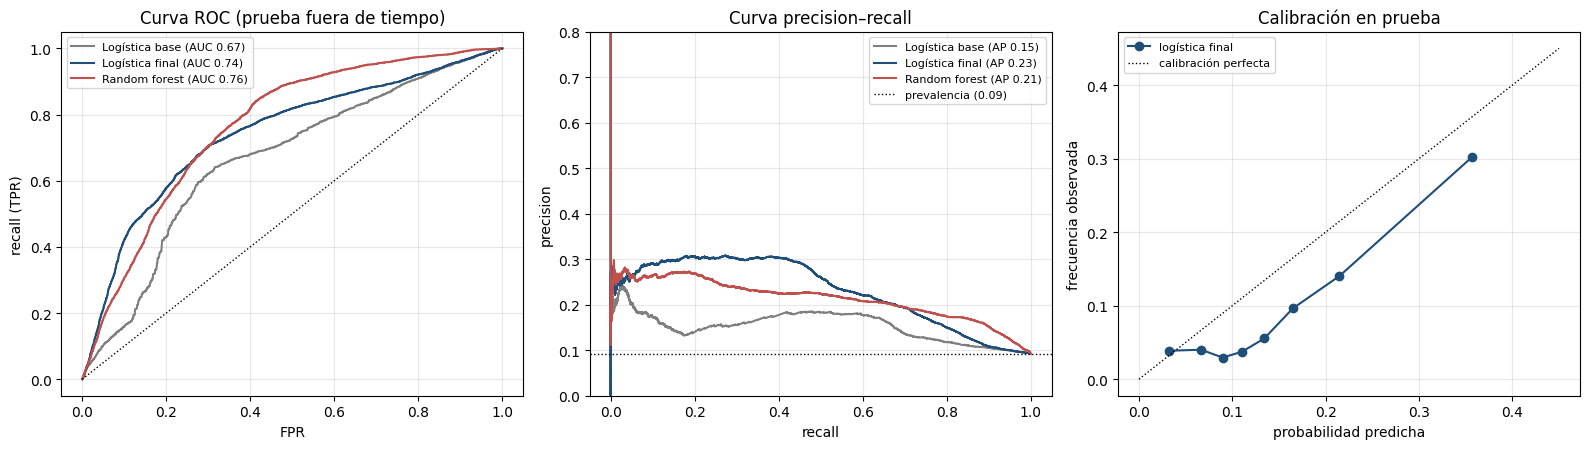

Calibración (predicha → observada): ['0.03 → 0.04', '0.07 → 0.04', '0.09 → 0.03', '0.11 → 0.04', '0.13 → 0.06', '0.16 → 0.10', '0.21 → 0.14', '0.36 → 0.30']


,contratos,tasa_adicion
quintil_hist_ent,,
Q1,10219,0.015
Q2,10248,0.031
Q3,10208,0.070
Q4,10218,0.091
Q5,10200,0.256


In [31]:
lg = sm.Logit(tr["y"], sm.add_constant(tr[FINAL].astype(float))).fit(disp=0)
esc = pd.Series(1.0, index=lg.params.index); esc[["hist_ent", "hist_prov"]] = 0.10      # OR por 10 p.p. en las tasas historicas
ci = lg.conf_int()
tab_or = pd.DataFrame({"OR": np.exp(lg.params * esc), "IC95 inf": np.exp(ci[0] * esc), "IC95 sup": np.exp(ci[1] * esc), "p": lg.pvalues}).drop("const").round(3)
display(tab_or)

mod_final = logistica().fit(tr[FINAL], tr["y"])
p_tr, p_te = mod_final.predict_proba(tr[FINAL])[:, 1], mod_final.predict_proba(te[FINAL])[:, 1]
print(f"Modelo final ({len(FINAL)} variables) en prueba: AUC = {roc_auc_score(te['y'], p_te):.3f} | AP = {average_precision_score(te['y'], p_te):.3f} | prevalencia = {te['y'].mean():.3f}")
um = []
for q in (.80, .90, .95):
    t = np.quantile(p_tr, q); pred = p_te >= t; vn, fp, fn, vp = confusion_matrix(te["y"], pred).ravel()
    um.append({"umbral (cuantil de entrenamiento)": f"{q:.0%}", "t": round(t, 3), "% de contratos marcados": round(pred.mean() * 100, 1), "VP": vp, "FP": fp, "FN": fn, "VN": vn,
               "precision": round(vp / (vp + fp), 3), "recall": round(vp / (vp + fn), 3)})
display(pd.DataFrame(um).set_index("umbral (cuantil de entrenamiento)"))

cv = StratifiedKFold(5, shuffle=True, random_state=42)
for nom, cols in [("base", BASE), ("final", FINAL)]:
    s = cross_val_score(logistica(), tr[cols], tr["y"], cv=cv, scoring="roc_auc"); print(f"Validación cruzada dentro de entrenamiento, modelo {nom}: AUC = {s.mean():.3f} ± {s.std():.3f}")
trB, teB = seg[seg["fecha_firma"] < "2023-11-01"], seg[seg["fecha_firma"] >= "2024-11-01"]
for nom, cols in [("base", BASE), ("base + banderas OCP", BASE + BANDERAS), ("final", FINAL)]:
    r, _ = evaluar(nom, cols, tr=trB, te=teB); print(f"Corte alterno (prueba nov-2024 a oct-2025, n={len(teB):,}, prevalencia {teB['y'].mean():.1%}), modelo {nom}: AUC = {r['AUC prueba']:.3f} | AP = {r['AP prueba']:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
curvas = [("Logística base", p_base, "#7f7f7f"), ("Logística final", p_te, "#1f4e79"), ("Random forest", P["Random forest (todas)"], "#c0504d")]
for nom, p, col in curvas:
    fpr, tpr, _ = roc_curve(te["y"], p); ax[0].plot(fpr, tpr, color=col, label=f"{nom} (AUC {roc_auc_score(te['y'], p):.2f})")
    pr_, rc_, _ = precision_recall_curve(te["y"], p); ax[1].plot(rc_, pr_, color=col, label=f"{nom} (AP {average_precision_score(te['y'], p):.2f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("recall (TPR)"); ax[0].set_title("Curva ROC (prueba fuera de tiempo)")
ax[1].axhline(te["y"].mean(), color="k", ls=":", lw=1, label=f"prevalencia ({te['y'].mean():.2f})"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Curva precision–recall"); ax[1].set_ylim(0, .8)
fr, mp = calibration_curve(te["y"], p_te, n_bins=8, strategy="quantile")
ax[2].plot(mp, fr, "o-", color="#1f4e79", label="logística final"); ax[2].plot([0, .45], [0, .45], "k:", lw=1, label="calibración perfecta")
ax[2].set_xlabel("probabilidad predicha"); ax[2].set_ylabel("frecuencia observada"); ax[2].set_title("Calibración en prueba")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(AQUI, "Figuras", "fig_evaluacion_logistica.png"), dpi=300, bbox_inches="tight"); plt.show()
print("Calibración (predicha → observada):", [f"{a:.2f} → {b_:.2f}" for a, b_ in zip(mp, fr)])
te.assign(quintil_hist_ent=pd.qcut(te["hist_ent"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])).groupby("quintil_hist_ent", observed=True)["y"].agg(contratos="size", tasa_adicion="mean").round(3)

In [32]:
# Robustez: la Gobernacion de Boyaca pesa mucho en el resultado. ¿El modelo sigue sirviendo sin ella?
es_gob = seg["nombre_entidad"].eq("GOBERNACIÓN DE BOYACÁ")
g_te = te["nombre_entidad"].eq("GOBERNACIÓN DE BOYACÁ")
print(f"Gobernación de Boyacá: {es_gob.mean():.1%} de los contratos con seguimiento | en prueba: {g_te.mean():.1%} de los contratos y {te.loc[g_te, 'y'].sum() / te['y'].sum():.1%} de las adiciones (tasa {te.loc[g_te, 'y'].mean():.1%} frente a {te.loc[~g_te, 'y'].mean():.1%} en el resto)")
tr_sg, te_sg = tr[~tr["nombre_entidad"].eq("GOBERNACIÓN DE BOYACÁ")], te[~g_te]
rob = []
for nom, cols in [("Logística base", BASE), ("Logística base + banderas OCP", BASE + BANDERAS), ("Logística final", FINAL)]:
    r, _ = evaluar(nom, cols, tr=tr_sg, te=te_sg); rob.append(r)
print(f"Sin la Gobernación (entrenamiento {len(tr_sg):,}, prueba {len(te_sg):,}, prevalencia {te_sg['y'].mean():.1%}):")
display(pd.DataFrame(rob).set_index("modelo").round(3))
n_q5 = te.loc[te["hist_ent"] >= te["hist_ent"].quantile(.8), "nit_entidad"].nunique()
print(f"Entidades en prueba: {te['nit_entidad'].nunique()} | en el quintil más alto de historia: {n_q5}")

Gobernación de Boyacá: 20.9% de los contratos con seguimiento | en prueba: 16.0% de los contratos y 51.1% de las adiciones (tasa 29.6% frente a 5.4% en el resto)
Sin la Gobernación (entrenamiento 20,558, prueba 42,926, prevalencia 5.4%):


,variables,AUC entrenamiento,AUC prueba,AP prueba,precision en el 10 % más alto,recall en el 10 % más alto
modelo,,,,,,
Logística base,8,0.792,0.698,0.125,0.157,0.291
Logística base + banderas OCP,19,0.840,0.756,0.135,0.152,0.283
Logística final,15,0.842,0.761,0.142,0.160,0.297


Entidades en prueba: 288 | en el quintil más alto de historia: 20


> **Lectura del modelo final (15 variables).**
> - **Qué pesa (odds ratios):**
>   - Plazo planeado: OR 1,91 por unidad de logaritmo. Un contrato con el doble de plazo tiene ≈ 57 % más *odds* de adición.
>   - Valor inicial: OR 1,24 por unidad de logaritmo (≈ 16 % más *odds* al duplicar el valor).
>   - Historia de la entidad: OR 1,16 por cada 10 puntos porcentuales de tasa histórica. Historia del proveedor: OR 1,26 por cada 10 puntos.
>   - Compraventa (OR 3,50) y suministros (1,96) se adicionan más que la prestación de servicios; el proveedor nuevo, menos (0,56).
>   - `bajo_tope` entra con OR 1,38 (p = 0,005), pero su aporte fuera de tiempo es casi nulo (Δ AUC +0,002): asociada, no útil para predecir.
> - **Desempeño fuera de tiempo:** AUC 0,742 y AP 0,230, frente a una prevalencia de 0,093.
> - **Umbral por capacidad:** si se revisa el ≈ 8,5 % de contratos con mayor puntaje (umbral fijado en entrenamiento), el 30,6 % termina con adición (precision) y ahí está el 28,0 % de todas las adiciones (recall). Revisando el 15 % se encuentra el 46,9 %. Revisar al azar daría 9,3 %.
> - **Gradiente por historia de la entidad:** en prueba, la tasa de adición va de 1,5 % en el quintil más bajo a 25,6 % en el más alto.
> - **Calibración:** el modelo **sobreestima** (predice 0,13 donde ocurre 0,06) porque la tasa de adición bajó de 16,4 % en entrenamiento a 9,3 % en prueba. Sirve para **ordenar**, no para leer el puntaje como probabilidad.
> - **Estabilidad:** validación cruzada dentro de entrenamiento 0,727 ± 0,005. Con el corte alterno el AUC del modelo final es 0,818 (base 0,698): la conclusión se mantiene y el tamaño de la mejora depende del periodo.
> - **Robustez (celda siguiente):** la Gobernación de Boyacá aporta el 16 % de los contratos de prueba y el 51 % de las adiciones (tasa de 29,6 % frente a 5,4 % en el resto). Al repetir todo sin ella:
>   - El modelo final sigue superando a la base: AUC 0,761 frente a 0,698.
>   - **Las banderas OCP sí aportan:** base + banderas llega a 0,756. La conclusión "las banderas no mejoran la predicción" vale para la base completa, donde una entidad domina; en el resto de entidades sí ayudan a ordenar.
>   - La ganancia práctica es menor: el AP pasa de 0,125 a 0,142 y la precision en el 10 % más alto queda en 16 % (prevalencia 5,4 %).
>   - Parte del poder del modelo completo es identificar a una entidad grande que adiciona mucho.

## 15. Supervivencia con variables limpias: Cox para la adición en valor
Se rehace el modelo de Cox solo para la adición en valor, con el valor inicial y el plazo planeado, y se compara el C-index fuera de tiempo (entrenar con firmados antes de 2025, probar con 2025 en adelante). El C-index es la misma idea del AUC con censura: la probabilidad de ordenar bien un par de contratos.

In [33]:
ev_t = (m["f_valor"] - m["fecha_firma"]).dt.days
cx = m.assign(evento=(m["f_valor"].notna() & (ev_t >= 0)).astype(int))
cx["tiempo"] = np.where(cx["evento"] == 1, ev_t, (CORTE - cx["fecha_firma"]).dt.days)
cx = cx[cx["tiempo"] >= 0].copy(); cx["tiempo"] = cx["tiempo"].clip(lower=.5)
trc = cx["fecha_firma"] < "2025-01-01"
print(f"Cox de adición en valor: {len(cx):,} contratos, {int(cx['evento'].sum()):,} eventos | entrena {trc.sum():,} | prueba {(~trc).sum():,} ({int(cx.loc[~trc, 'evento'].sum()):,} eventos)")
for nom, cols in [("base (valor inicial, plazo, grupo, tipo)", BASE), ("base + banderas OCP", BASE + BANDERAS), ("modelo final (selección por AIC)", FINAL)]:
    X = cx[cols].astype(float); X = (X - X[trc].mean()) / X[trc].std()
    mt = PHReg(cx.loc[trc, "tiempo"].values, X[trc].values, status=cx.loc[trc, "evento"].values, ties="breslow").fit()
    riesgo = (X[~trc].values * mt.params).sum(axis=1)
    print(f"  {nom:42s} C-index fuera de tiempo = {cindex(cx.loc[~trc, 'tiempo'].values, cx.loc[~trc, 'evento'].values, riesgo):.3f}")
Xc = cx[FINAL].astype(float); esc_c = np.where(np.isin(FINAL, ["hist_ent", "hist_prov"]), 0.10, 1.0)
mc_ = PHReg(cx["tiempo"].values, Xc.values, status=cx["evento"].values, ties="breslow").fit()
pd.DataFrame({"HR": np.exp(mc_.params * esc_c), "IC95 inf": np.exp((mc_.params - 1.96 * mc_.bse) * esc_c), "IC95 sup": np.exp((mc_.params + 1.96 * mc_.bse) * esc_c), "p": mc_.pvalues}, index=FINAL).round(3)

Cox de adición en valor: 128,574 contratos, 14,369 eventos | entrena 73,785 | prueba 54,789 (4,828 eventos)


  base (valor inicial, plazo, grupo, tipo)   C-index fuera de tiempo = 0.695


  base + banderas OCP                        C-index fuera de tiempo = 0.688


  modelo final (selección por AIC)           C-index fuera de tiempo = 0.809


,HR,IC95 inf,IC95 sup,p
ldur0,1.598,1.557,1.639,0.000
lv0,1.246,1.228,1.264,0.000
hist_prov,1.166,1.147,1.185,0.000
prov_nuevo,0.810,0.774,0.849,0.000
hist_ent,1.603,1.584,1.622,0.000
t_Compraventa,1.432,1.272,1.611,0.000
t_Suministros,1.092,1.008,1.182,0.031
g_Directa con ofertas,0.586,0.525,0.655,0.000
t_Otro,0.599,0.554,0.649,0.000
g_Régimen especial,1.205,1.104,1.316,0.000


> **Lectura.** Con variables limpias el Cox de adición en valor ordena mejor que el de la sección 9: C-index 0,695 con la base y **0,809** con el modelo final (el 0,60 anterior era para "cualquier modificación" y con variables contaminadas). Las banderas OCP de firma tampoco mejoran aquí en la base completa (0,688). Los *hazard ratios* coinciden en sentido con los *odds ratios* de la logística: plazo, valor, historia de la entidad (HR 1,60 por cada 10 puntos) y modalidades con competencia (HR 1,79). Dos métodos distintos para tratar la censura llegan a la misma conclusión.

### 15.1 ¿Cuándo llegan las modificaciones?
Las curvas de Kaplan–Meier de la sección 8 bajan en escalones cerca de los 90 y 180 días. Aquí se mide en qué momento aparecen las modificaciones, de dos formas que no se sesgan por la censura:

1. **Días hasta que se modifica el 5 %, 10 % y 25 % de cada grupo,** leídos de la curva de Kaplan–Meier. No sirve promediar los días de los contratos modificados: los recientes solo alcanzan a mostrar modificaciones tempranas y el promedio saldría corto.
2. **Momento de la modificación como porcentaje del plazo planeado** (días hasta la modificación ÷ plazo planeado de la sección 12). Solo entran contratos cuyo plazo venció al menos 180 días antes del corte, para que todos hayan tenido la misma oportunidad de mostrar la modificación.


n  días hasta 5 %  días hasta 10 %  días hasta 25 %
evento                 grupo normativo                                                              
Cualquier modificación Directa con ofertas    3500               5               12             40.0
                       Estatuto General     122032               0                8             97.0
                       Régimen especial      16178               6               25             96.0
Adición en valor       Directa con ofertas    3500              90              118              NaN
                       Estatuto General     122032             186              243              NaN
                       Régimen especial      16178              92              211              NaN

Contratos con plazo planeado vencido hace al menos 180 días: 108,253
Plazos planeados más frecuentes (días): {120.0: 9.9, 180.0: 8.3, 240.0: 7.2, 90.0: 6.7, 150.0: 6.7, 30.0: 5.3}
Cualquier modificación: 49,765 contratos (46.0%) | mediana 65% del plazo | antes de la mitad del plazo: 43.6% | entre 75 % y 105 % del plazo: 36.8% | después del fin: 9.0%
Adición en valor: 12,566 contratos (11.6%) | mediana 98% del plazo | antes de la mitad del plazo: 11.7% | entre 75 % y 105 % del plazo: 62.9% | después del fin: 13.1%
Tipo de las modificaciones en el primer 5 % del plazo: {'general': 97.3, 'valor': 2.4, 'suspension': 0.2, 'cesion': 0.1}
Tipo de las modificaciones entre 75 % y 105 % del plazo: {'general': 75.7, 'valor': 19.0, 'suspension': 4.7, 'cesion': 0.5}


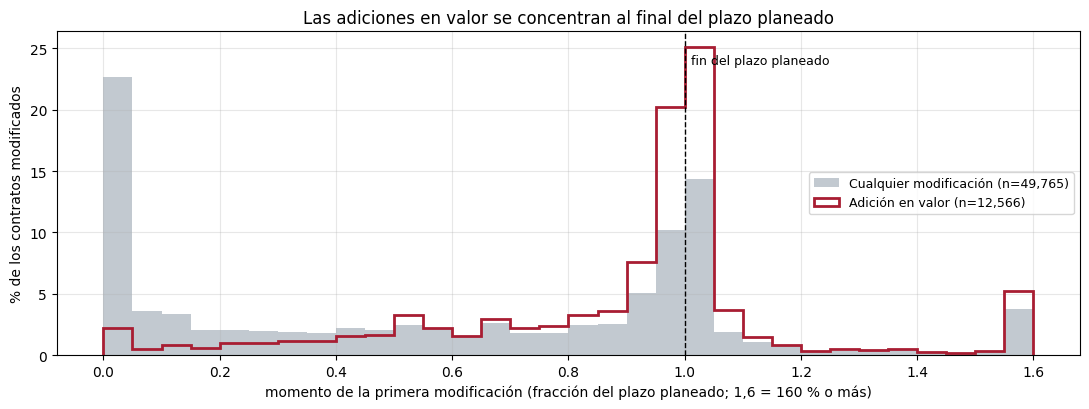

In [34]:
# Medida 1: dias hasta que se modifica el 5 %, 10 % y 25 % de cada grupo (Kaplan-Meier)
def dias_hasta(g, q):
    sf = SurvfuncRight(g["tiempo"], g["evento"]); acum = 1 - sf.surv_prob
    return int(sf.surv_times[np.argmax(acum >= q)]) if (acum >= q).any() else np.nan
filas = []
for ev_nom, d in [("Cualquier modificación", S["cualquiera"]), ("Adición en valor", S["valor"])]:
    for nombre, g in d.groupby("grupo_normativo"):
        if len(g) < 500: continue
        filas.append({"evento": ev_nom, "grupo normativo": nombre, "n": len(g), **{f"días hasta {int(q * 100)} %": dias_hasta(g, q) for q in (.05, .10, .25)}})
display(pd.DataFrame(filas).set_index(["evento", "grupo normativo"]))

# Medida 2: momento de la modificacion como fraccion del plazo planeado
fin_plazo = f["fecha_firma"] + pd.to_timedelta(f["dur0"], unit="D")
completo = f["dur0"].notna() & (fin_plazo + pd.Timedelta(days=180) <= CORTE)
print(f"Contratos con plazo planeado vencido hace al menos 180 días: {completo.sum():,}")
print("Plazos planeados más frecuentes (días):", f.loc[completo, "dur0"].round().value_counts(normalize=True).head(6).mul(100).round(1).to_dict())
mom = {}
for nom, col in [("Cualquier modificación", "f_cualquiera"), ("Adición en valor", "f_valor")]:
    t = (f[col] - f["fecha_firma"]).dt.days
    r = (t / f["dur0"])[completo & f[col].notna() & (t >= 0)]; mom[nom] = r
    print(f"{nom}: {len(r):,} contratos ({len(r) / completo.sum():.1%}) | mediana {r.median():.0%} del plazo | "
          f"antes de la mitad del plazo: {(r < .5).mean():.1%} | entre 75 % y 105 % del plazo: {r.between(.75, 1.05).mean():.1%} | después del fin: {(r > 1.05).mean():.1%}")

primer_tipo = ev.sort_values("fecha_ev").drop_duplicates("id_contrato").set_index("id_contrato")["clase"]
r = mom["Cualquier modificación"]
print("Tipo de las modificaciones en el primer 5 % del plazo:", primer_tipo.reindex(r[r < .05].index).value_counts(normalize=True).mul(100).round(1).to_dict())
print("Tipo de las modificaciones entre 75 % y 105 % del plazo:", primer_tipo.reindex(r[r.between(.75, 1.05)].index).value_counts(normalize=True).mul(100).round(1).to_dict())

fig, ax = plt.subplots(figsize=(11, 4.2))
bins = np.arange(0, 1.65, .05)
for (nom, r), col in zip(mom.items(), ["#9aa5b1", "#a81d32"]):
    ax.hist(r.clip(upper=1.6), bins=bins, weights=np.full(len(r), 100 / len(r)), histtype="stepfilled" if col == "#9aa5b1" else "step",
            lw=2, color=col, alpha=.6 if col == "#9aa5b1" else 1, label=f"{nom} (n={len(r):,})")
ax.axvline(1, color="k", ls="--", lw=1); ax.text(1.01, ax.get_ylim()[1] * .9, "fin del plazo planeado", fontsize=9)
ax.set_xlabel("momento de la primera modificación (fracción del plazo planeado; 1,6 = 160 % o más)"); ax.set_ylabel("% de los contratos modificados")
ax.set_title("Las adiciones en valor se concentran al final del plazo planeado"); ax.legend(fontsize=9); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(AQUI, "Figuras", "fig_momento_modificacion.png"), dpi=300, bbox_inches="tight"); plt.show()


> **Lectura.**
> - **Cualquier modificación llega pronto:** el 5 % de los contratos se modifica entre el día 0 y el 6, y el 25 % entre los 40 y los 97 días. En el histograma se ve por qué: el 22 % de esas modificaciones ocurre en el primer 5 % del plazo, y el 97 % de ellas son *modificaciones generales*, ajustes poco después de la firma. Es otra razón para no usar "cualquier modificación" como resultado.
> - **La adición en valor llega al final del plazo.** La mediana ocurre al 98 % del plazo planeado, y el 62,9 % cae entre el 75 % y el 105 %. Solo el 11,7 % llega antes de la mitad. En días, el 10 % de los contratos se adiciona a los 118 días en Directa con ofertas y a los 243 en Estatuto General; ningún grupo llega al 25 %.
> - **Eso explica los escalones de la sección 8.** Los plazos más frecuentes son 120, 180, 240, 90 y 150 días, y las adiciones se acumulan justo cuando esos plazos vencen.
> - El 13,1 % de las adiciones se registra después del fin del plazo planeado, y una parte queda en 160 % o más. Pueden ser contratos que primero se prorrogaron y después se adicionaron, o registros tardíos en la bitácora; con estos datos no se puede distinguir.
> - **Implicación para la veeduría:** entre la firma y la adición suele pasar casi todo el plazo. Una alerta calculada al firmar deja meses para revisar el contrato antes de que llegue la adición. También ayuda a entender por qué el plazo planeado es la variable que más pesa en el modelo (OR 1,91): cuanto más largo el plazo, más tiempo y más motivos hay para ajustar el contrato al final.


## 16. Modelo del valor inicial y residuo como señal de alerta
Cuarta línea de la retroalimentación: un contrato que se aleja de lo que predice el modelo puede ser la señal más útil.

- **Objetivo:** `log` del valor inicial (no el vigente). Trece predictores interpretables: plazo planeado, persona natural, pyme, entidad nacional, mínima cuantía, modalidad con competencia, enero, grupo normativo y tipo de contrato.
- **Mínimos cuadrados con diagnóstico** (sesiones 4 y 7): Q-Q de residuos, residuos contra ajustados y Breusch-Pagan.
- **`BayesianRidge`** (sesión 13, mi tema): da un intervalo de predicción por contrato. Supone ruido constante, así que se mide la **cobertura real del intervalo del 95 %** por tipo de contrato y por mes antes de usarlo.
- Misma partición temporal: se entrena con firmados antes de 2023 y se evalúa con los firmados desde 2024.

,coef,exp(coef),IC95 inf,IC95 sup,p
const,15.330,4548819.150,15.258,15.403,0.000
ldur0,0.485,1.625,0.472,0.499,0.000
natural,-1.341,0.262,-1.373,-1.309,0.000
pyme,0.061,1.063,0.030,0.093,0.000
nacional,-0.046,0.955,-0.074,-0.018,0.001
mc,-1.991,0.137,-2.050,-1.933,0.000
competitiva,1.590,4.904,1.534,1.646,0.000
enero,0.204,1.227,0.175,0.234,0.000
g_Directa con ofertas,-1.557,0.211,-1.662,-1.453,0.000
g_Régimen especial,0.367,1.443,0.307,0.427,0.000


R² en entrenamiento = 0.495 | Prueba fuera de tiempo: RMSE = 1.006 (en log), R² = 0.376 | Línea base (media de entrenamiento): RMSE = 1.273
Breusch-Pagan: LM = 1704.6, p = 0 (H0: varianza constante) | sesgo de residuos = -0.33 | exceso de curtosis = 10.91

BayesianRidge: desviación del ruido = 0.953 | desviación predictiva entre 0.953 y 0.955 (domina el ruido irreducible)
Cobertura del intervalo del 95 %: entrenamiento 93.7 % | prueba 93.7 %


,contratos (prueba),"cobertura, ruido constante (%)","cobertura, dispersión por tipo (%)",desv. del residuo en entrenamiento
tipo_c,,,,
Compraventa,2041,79.6,95.2,1.4
Decreto 092 de 2017,3287,86.9,93.0,1.2
Otro,8112,80.4,95.7,1.6
Prestación de servicios,62118,97.3,95.4,0.8
Suministros,5490,82.3,95.8,1.4


Cobertura por mes de firma, ruido constante (%): {1: 96.5, 2: 94.7, 3: 93.7, 4: 91.5, 5: 91.7, 6: 91.7, 7: 95.0, 8: 95.2, 9: 95.2, 10: 93.9, 11: 87.9, 12: 79.0}
Cobertura por mes de firma, dispersión por tipo (%): {1: 95.9, 2: 95.9, 3: 95.3, 4: 93.7, 5: 93.9, 6: 93.6, 7: 96.9, 8: 96.9, 9: 96.5, 10: 95.9, 11: 93.1, 12: 88.6}


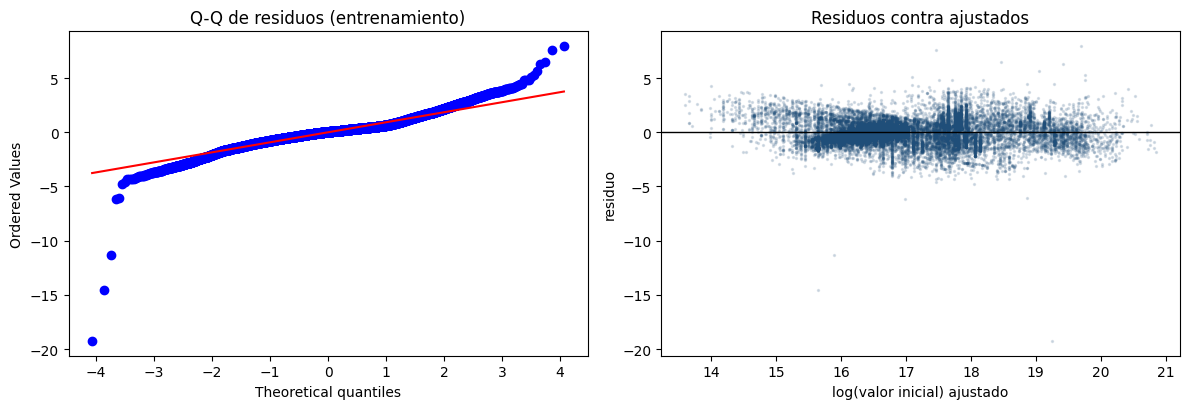

In [35]:
from sklearn.linear_model import BayesianRidge
from statsmodels.stats.diagnostic import het_breuschpagan
m["natural"] = m["tipodocproveedor"].eq("Cédula de Ciudadanía").astype(float)
m["pyme"] = m["es_pyme"].str.lower().eq("si").astype(float)
m["nacional"] = m["orden"].eq("Nacional").astype(float)
m["mc"] = m["es_mc"].astype(float)
VX = ["ldur0", "natural", "pyme", "nacional", "mc", "competitiva", "enero"] + list(DUM.columns)
vtr, vte = m[m["fecha_firma"] < "2023-01-01"], m[m["fecha_firma"] >= "2024-01-01"]
ols = sm.OLS(vtr["lv0"], sm.add_constant(vtr[VX].astype(float))).fit()
display(pd.DataFrame({"coef": ols.params, "exp(coef)": np.exp(ols.params), "IC95 inf": ols.conf_int()[0], "IC95 sup": ols.conf_int()[1], "p": ols.pvalues}).round(3))
pred = ols.predict(sm.add_constant(vte[VX].astype(float)))
rmse = np.sqrt(((vte["lv0"] - pred) ** 2).mean()); r2 = 1 - ((vte["lv0"] - pred) ** 2).sum() / ((vte["lv0"] - vte["lv0"].mean()) ** 2).sum()
rmse0 = np.sqrt(((vte["lv0"] - vtr["lv0"].mean()) ** 2).mean())
print(f"R² en entrenamiento = {ols.rsquared:.3f} | Prueba fuera de tiempo: RMSE = {rmse:.3f} (en log), R² = {r2:.3f} | Línea base (media de entrenamiento): RMSE = {rmse0:.3f}")
bp = het_breuschpagan(ols.resid, ols.model.exog)
print(f"Breusch-Pagan: LM = {bp[0]:.1f}, p = {bp[1]:.2g} (H0: varianza constante) | sesgo de residuos = {stats.skew(ols.resid):.2f} | exceso de curtosis = {stats.kurtosis(ols.resid):.2f}")

sc = StandardScaler().fit(vtr[VX]); br = BayesianRidge().fit(sc.transform(vtr[VX]), vtr["lv0"])
mu, sd = br.predict(sc.transform(m[VX]), return_std=True)
m["resid"] = m["lv0"] - mu; m["z"] = m["resid"] / sd
sd_tipo = m.loc[vtr.index].groupby("tipo_c")["resid"].std()            # dispersion por tipo, estimada solo en entrenamiento
m["z_tipo"] = m["resid"] / m["tipo_c"].map(sd_tipo)
vtr, vte = m.loc[vtr.index], m.loc[vte.index]
print(f"\nBayesianRidge: desviación del ruido = {np.sqrt(1 / br.alpha_):.3f} | desviación predictiva entre {sd.min():.3f} y {sd.max():.3f} (domina el ruido irreducible)")
cob = lambda d, col: (d[col].abs() <= 1.96).mean() * 100
print(f"Cobertura del intervalo del 95 %: entrenamiento {cob(vtr, 'z'):.1f} % | prueba {cob(vte, 'z'):.1f} %")
tab_cob = pd.DataFrame({"contratos (prueba)": vte.groupby("tipo_c").size(),
                        "cobertura, ruido constante (%)": vte.groupby("tipo_c").apply(lambda d: cob(d, "z")),
                        "cobertura, dispersión por tipo (%)": vte.groupby("tipo_c").apply(lambda d: cob(d, "z_tipo")),
                        "desv. del residuo en entrenamiento": sd_tipo}).round(1)
display(tab_cob)
print("Cobertura por mes de firma, ruido constante (%):", vte.groupby(vte["fecha_firma"].dt.month).apply(lambda d: cob(d, "z")).round(1).to_dict())
print("Cobertura por mes de firma, dispersión por tipo (%):", vte.groupby(vte["fecha_firma"].dt.month).apply(lambda d: cob(d, "z_tipo")).round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
stats.probplot(ols.resid, dist="norm", plot=ax[0]); ax[0].set_title("Q-Q de residuos (entrenamiento)")
mu_tr = ols.fittedvalues; ax[1].scatter(mu_tr, ols.resid, s=2, alpha=.15, color="#1f4e79"); ax[1].axhline(0, color="k", lw=1)
ax[1].set_xlabel("log(valor inicial) ajustado"); ax[1].set_ylabel("residuo"); ax[1].set_title("Residuos contra ajustados")
plt.tight_layout(); plt.savefig(os.path.join(AQUI, "Figuras", "fig_residuos.png"), dpi=300, bbox_inches="tight"); plt.show()

> **Lectura.**
> - El modelo explica la mitad de la variación del valor inicial en entrenamiento (R² 0,495) y 0,376 fuera de tiempo; reduce el error frente a la línea base (RMSE 1,006 frente a 1,273 en logaritmos). Un error de 1,0 en logaritmo es un factor de ≈ 2,7: el valor de un contrato individual se predice con poca precisión.
> - Coeficientes legibles: una persona natural contrata por ≈ 26 % del valor de una jurídica comparable; la mínima cuantía, por ≈ 14 %; en enero los contratos son ≈ 23 % más grandes (se firma el año completo).
> - **Los supuestos no se cumplen:** Breusch-Pagan rechaza la varianza constante y los residuos tienen colas pesadas (exceso de curtosis 10,9).
> - **Por eso el intervalo bayesiano de ruido constante engaña:** cubre 93,7 % en total, pero 97,3 % en prestación de servicios y solo 79,6 % en compraventa. Es lo que advertía mi exposición de la sesión 13. Con la dispersión estimada por tipo de contrato la cobertura queda entre 93,0 % y 95,8 % en todos los tipos. Diciembre sigue bajo (88,6 %).

### 16.1 ¿El residuo sirve como alerta?
Bandera: contrato cuyo valor inicial queda **por encima** del intervalo del 95 % (más caro de lo esperado para su tipo, modalidad, plazo y clase de proveedor), usando la dispersión propia de su tipo de contrato. Se revisa si esos contratos terminan con más adiciones y si la bandera mejora el modelo de la sección 14.

In [36]:
m["resid_alto"] = (m["z_tipo"] > 1.96).astype(int); m["resid_bajo"] = (m["z_tipo"] < -1.96).astype(int)
seg = m[m["fecha_firma"] <= CORTE - pd.Timedelta(days=H)]
tr, te = seg[seg["fecha_firma"] < "2023-01-01"], seg[seg["fecha_firma"] >= "2024-01-01"]
te_r = te.assign(grupo_residuo=np.select([te["resid_alto"] == 1, te["resid_bajo"] == 1], ["por encima del intervalo", "por debajo del intervalo"], "dentro del intervalo"))
display(te_r.groupby("grupo_residuo")["y"].agg(contratos="size", tasa_adicion_365d="mean").assign(porcentaje_de_contratos=lambda d: d["contratos"] / len(te_r) * 100).round(3))
c2, p_, _, _ = stats.chi2_contingency(pd.crosstab(te_r["resid_alto"], te_r["y"]))
print(f"Por encima del intervalo frente al resto: chi2 = {c2:.1f}, p = {p_:.2g}, V de Cramér = {np.sqrt(c2 / len(te_r)):.3f}")
for nom, cols in [("modelo final", FINAL), ("modelo final + residuo estandarizado", FINAL + ["z_tipo"]), ("modelo final + bandera de residuo alto", FINAL + ["resid_alto"])]:
    r, _ = evaluar(nom, cols, tr=tr, te=te); print(f"  {nom:40s} AUC = {r['AUC prueba']:.3f} | AP = {r['AP prueba']:.3f}")
print("\nContratos de prueba por encima del intervalo, por tipo:", te_r[te_r["resid_alto"] == 1].groupby("tipo_c").size().to_dict())

,contratos,tasa_adicion_365d,porcentaje_de_contratos
grupo_residuo,,,
dentro del intervalo,48825,0.093,95.561
por debajo del intervalo,1027,0.054,2.010
por encima del intervalo,1241,0.098,2.429


Por encima del intervalo frente al resto: chi2 = 0.4, p = 0.51, V de Cramér = 0.003
  modelo final                             AUC = 0.742 | AP = 0.230
  modelo final + residuo estandarizado     AUC = 0.724 | AP = 0.214
  modelo final + bandera de residuo alto   AUC = 0.742 | AP = 0.231

Contratos de prueba por encima del intervalo, por tipo: {'Compraventa': 45, 'Decreto 092 de 2017': 65, 'Otro': 105, 'Prestación de servicios': 928, 'Suministros': 98}


> **Lectura.** El 2,4 % de los contratos de prueba queda por encima del intervalo. Su tasa de adición (9,8 %) es igual a la del resto (9,3 %; p = 0,51), y agregar el residuo al modelo final no mejora el AUC. **El residuo no anticipa la adición en valor.**
>
> No por eso se descarta: mide otra cosa. La adición dice que el contrato creció después de firmado; el residuo dice que **arrancó** caro para sus características. Son dos listas de revisión distintas. Con una desviación de ≈ 1 en logaritmos, el residuo solo identifica casos extremos (más de 6 veces el valor esperado), y para decir que un precio es alto haría falta comparar contra precios de mercado del mismo bien, que estos datos no traen.

## 17. Ley de Garantías: contraste con pruebas de hipótesis
La Ley 996 de 2005 (art. 33) restringe la contratación directa durante los cuatro meses anteriores a la elección presidencial y hasta la segunda vuelta. Para las elecciones regionales la restricción es otra y más estrecha (parágrafo del art. 38: convenios interadministrativos), por eso no se espera la misma caída.

- Se analiza solo el **Estatuto General**: el régimen especial no aplica estas reglas de la misma forma.
- Prueba **chi-cuadrado** (sesión 3) de la proporción de contratación directa *durante* frente a *antes*, con diferencia en puntos porcentuales y V de Cramér.
- **Comparación contra años sin elección presidencial:** la misma ventana del calendario en 2023, 2024 y 2025. Se usa del 1-feb al 19-jun porque es el tramo que cae dentro de la restricción tanto en 2022 como en 2026. Así no se confunde la restricción con la estacionalidad normal de la contratación.

,n antes,n durante,n después,% directa antes,% directa durante,% directa después,durante − antes (p.p.),chi2,p,V de Cramér
periodo,,,,,,,,,,
Presidencial 2022,7193,2177,4702,89.6,64.5,84.1,-25.1,770.6,"< 0,001",0.29
Regionales 2023,5911,3463,7422,86.1,73.1,80.7,-13.1,244.5,"< 0,001",0.16
Presidencial 2026,18129,2787,9779,86.2,8.7,81.2,-77.5,7930.8,"< 0,001",0.62


,elección presidencial,contratos 1–28 ene,"directas por día, 1–28 ene",contratos 1-feb a 19-jun,% directa 1-feb a 19-jun,"directas por día, 1-feb a 19-jun"
año,,,,,,
2021,no,810,28.4,3915,92.5,26.1
2022,sí,4960,176.1,2055,62.9,9.3
2023,no,1861,65.4,7893,89.3,50.7
2024,no,1493,49.2,10044,83.6,60.4
2025,no,3268,111.6,10976,81.2,64.1
2026,sí,10283,361.8,2724,7.3,1.4


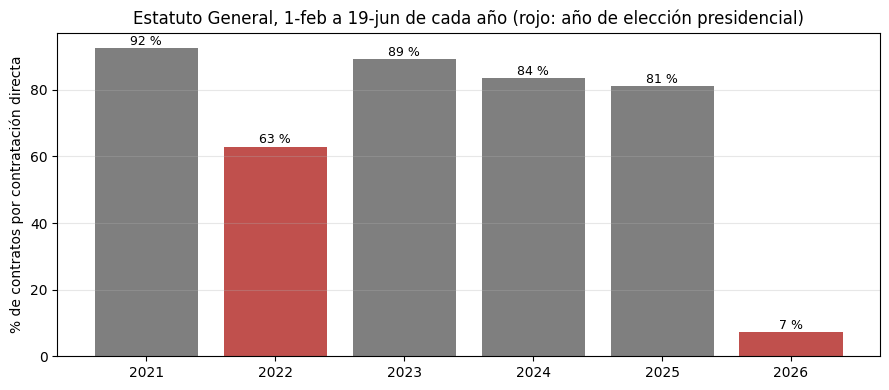

Directas del Estatuto General entre 1-feb y 19-jun de 2022: 1,292; en febrero: 1,159; por 'Servicios profesionales y apoyo a la gestión': 1,249
Entidades con más contratos: {'GOBERNACIÓN DE BOYACÁ': 744, 'METUN': 141, 'MUNICIPIO DE DUITAMA': 116, 'MUNICIPIO DE TUNJA/': 97}


In [37]:
eg = f[f["grupo_normativo"] == "Estatuto General"]
filas = []
for nom, i, fin in LEY_GARANTIAS:
    i, fin = pd.Timestamp(i), pd.Timestamp(fin); dur = (fin - i).days
    ant = eg[(eg["fecha_firma"] >= i - pd.Timedelta(days=dur)) & (eg["fecha_firma"] < i)]
    du = eg[(eg["fecha_firma"] >= i) & (eg["fecha_firma"] <= fin)]
    de_ = eg[(eg["fecha_firma"] > fin) & (eg["fecha_firma"] <= fin + pd.Timedelta(days=dur))]
    tabla = np.array([[ant["directa"].sum(), (~ant["directa"]).sum()], [du["directa"].sum(), (~du["directa"]).sum()]])
    c2, p_, _, _ = stats.chi2_contingency(tabla)
    filas.append({"periodo": nom, "n antes": len(ant), "n durante": len(du), "n después": len(de_), "% directa antes": ant["directa"].mean() * 100, "% directa durante": du["directa"].mean() * 100,
                  "% directa después": de_["directa"].mean() * 100, "durante − antes (p.p.)": (du["directa"].mean() - ant["directa"].mean()) * 100, "chi2": c2, "p": p_, "V de Cramér": np.sqrt(c2 / tabla.sum())})
tab_lg = pd.DataFrame(filas).set_index("periodo")
tab_lg["p"] = tab_lg["p"].map(lambda x: "< 0,001" if x < .001 else f"{x:.3f}"); tab_lg["V de Cramér"] = tab_lg["V de Cramér"].map(lambda x: f"{x:.2f}")
display(tab_lg.round(1))

vent = []
for a in range(2021, 2027):
    w = eg[(eg["fecha_firma"] >= f"{a}-02-01") & (eg["fecha_firma"] <= f"{a}-06-19")]; e = eg[(eg["fecha_firma"] >= f"{a}-01-01") & (eg["fecha_firma"] < f"{a}-01-29")]
    vent.append({"año": a, "elección presidencial": "sí" if a in (2022, 2026) else "no", "contratos 1–28 ene": len(e), "directas por día, 1–28 ene": e["directa"].sum() / 28,
                 "contratos 1-feb a 19-jun": len(w), "% directa 1-feb a 19-jun": w["directa"].mean() * 100, "directas por día, 1-feb a 19-jun": w["directa"].sum() / 139})
tab_vent = pd.DataFrame(vent).set_index("año").round(1); display(tab_vent)

fig, ax = plt.subplots(figsize=(9, 4))
col = ["#c0504d" if e == "sí" else "#7f7f7f" for e in tab_vent["elección presidencial"]]
ax.bar(tab_vent.index.astype(str), tab_vent["% directa 1-feb a 19-jun"], color=col)
for x, v in zip(tab_vent.index.astype(str), tab_vent["% directa 1-feb a 19-jun"]): ax.text(x, v + 1, f"{v:.0f} %", ha="center", fontsize=9)
ax.set_ylabel("% de contratos por contratación directa"); ax.set_title("Estatuto General, 1-feb a 19-jun de cada año (rojo: año de elección presidencial)"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(AQUI, "Figuras", "fig_ley_garantias.png"), dpi=300, bbox_inches="tight"); plt.show()

feb22 = eg[(eg["fecha_firma"] >= "2022-02-01") & (eg["fecha_firma"] <= "2022-06-19") & eg["directa"]]
print(f"Directas del Estatuto General entre 1-feb y 19-jun de 2022: {len(feb22):,}; en febrero: {(feb22['fecha_firma'].dt.month == 2).sum():,}; por 'Servicios profesionales y apoyo a la gestión': {feb22['justificacion_modalidad_de'].str.startswith('Servicios profesionales').sum():,}")
print("Entidades con más contratos:", feb22["nombre_entidad"].str.slice(0, 40).value_counts().head(4).to_dict())

**Excepciones a la restricción.** El artículo 33 de la Ley 996 de 2005 permite contratar directamente durante la restricción en cinco casos: defensa y seguridad del Estado, crédito público, emergencias educativas, sanitarias y desastres, reconstrucción de infraestructura afectada por atentados o desastres, y la contratación de entidades sanitarias y hospitalarias. Tampoco aplica a los contratos con organismos internacionales del artículo 20 de la Ley 1150 de 2007. SECOP II no registra qué excepción se invocó, así que cada contrato directo firmado durante la restricción se clasifica con el sector, la justificación de la modalidad y el objeto.

In [38]:
# ¿Los contratos directos firmados durante la restricción caben en alguna excepción?
# Art. 33 de la Ley 996 de 2005: defensa y seguridad, crédito público, emergencias educativas, sanitarias y desastres,
# reconstrucción de infraestructura y entidades sanitarias y hospitalarias. SECOP II no registra la excepción invocada:
# se clasifica con lo que sí está en los datos (sector, justificación de la modalidad y objeto), en este orden.
SALUD = r"salud|hospital|e\.s\.e|empresa social del estado|m[eé]dic|enfermer|vacun|epidemiol|covid"
def excepcion(r):
    j = str(r["justificacion_modalidad_de"]).lower()
    if str(r["sector"]).lower() == "defensa" or "sujetos a reserva" in j: return "Defensa y seguridad"
    if "crédito público" in j or "credito publico" in j:                    return "Crédito público"
    if "urgencia manifiesta" in j:                                          return "Urgencia manifiesta"
    if "valor cero" in j:                                                   return "Convenio sin recursos (valor cero)"
    if pd.Series([f"{r['objeto_del_contrato']} {r['nombre_entidad']}"]).str.contains(SALUD, case=False).iloc[0]:
        return "Objeto de salud (posible excepción sanitaria)"
    return "Sin excepción visible"

ORDEN_EXC = ["Defensa y seguridad", "Crédito público", "Urgencia manifiesta", "Convenio sin recursos (valor cero)",
             "Objeto de salud (posible excepción sanitaria)", "Sin excepción visible"]
filas_exc, detalle_exc = {}, {}
for nom, i, fin in LEY_GARANTIAS:
    if not nom.startswith("Presidencial"): continue            # en las regionales la restricción es otra (art. 38)
    du = eg[eg["fecha_firma"].between(pd.Timestamp(i), pd.Timestamp(fin)) & eg["directa"]].copy()
    du["excepcion"] = du.apply(excepcion, axis=1)
    filas_exc[nom] = du["excepcion"].value_counts().reindex(ORDEN_EXC, fill_value=0)
    detalle_exc[nom] = du
tab_exc = pd.DataFrame(filas_exc)
tab_exc.loc["Total"] = tab_exc.sum()
display(tab_exc)

for nom, du in detalle_exc.items():
    sin = du[du["excepcion"].eq("Sin excepción visible")]
    print(f"\n{nom} — sin excepción visible: {len(sin):,} de {len(du):,} ({len(sin) / len(du):.0%})")
    print("  por justificación:", sin["justificacion_modalidad_de"].value_counts().head(4).to_dict())
    print("  entidades:", sin["nombre_entidad"].str.slice(0, 35).value_counts().head(4).to_dict())

g22 = detalle_exc["Presidencial 2022"]
g22 = g22[g22["nombre_entidad"].eq("GOBERNACIÓN DE BOYACÁ") & (g22["fecha_firma"].dt.month == 2)]
print(f"\nGobernación de Boyacá, febrero de 2022: {len(g22):,} directas; firmadas del 1 al 3 de febrero: {g22['fecha_firma'].dt.day.le(3).sum():,}; "
      f"con inicio anterior a la firma: {(g22['fecha_de_inicio_del_contrato'] < g22['fecha_firma']).sum():,}")
print("  por clasificación:", g22["excepcion"].value_counts().to_dict())


,Presidencial 2022,Presidencial 2026
excepcion,,
Defensa y seguridad,143,157
Crédito público,0,4
Urgencia manifiesta,1,2
Convenio sin recursos (valor cero),1,2
Objeto de salud (posible excepción sanitaria),211,5
Sin excepción visible,1049,72
Total,1405,242



Presidencial 2022 — sin excepción visible: 1,049 de 1,405 (75%)
  por justificación: {'Servicios profesionales y apoyo a la gestión': 1015, 'No existe pluralidad de oferentes en el mercado': 20, 'Arrendamiento de inmuebles': 14}
  entidades: {'GOBERNACIÓN DE BOYACÁ': 584, 'MUNICIPIO DE DUITAMA': 97, 'MUNICIPIO DE TUNJA/': 96, 'INSTITUTO DE LA JUVENTUD; EL DEPORT': 88}

Presidencial 2026 — sin excepción visible: 72 de 242 (30%)
  por justificación: {'Servicios profesionales y apoyo a la gestión': 61, 'No existe pluralidad de oferentes en el mercado': 4, 'Law2166of2021_Article95_SolidarityAgreements': 4, 'Arrendamiento de inmuebles': 3}
  entidades: {'MUNICIPIO DE LABRANZAGRANDE': 22, 'ALCALDIA MUNICIPAL SUSACON BOYACA': 9, 'MUNICIPIO DE FIRAVITOBA': 3, 'ALCALDIA MUNICIPAL DE MIRAFLORES BO': 3}

Gobernación de Boyacá, febrero de 2022: 744 directas; firmadas del 1 al 3 de febrero: 742; con inicio anterior a la firma: 0
  por clasificación: {'Sin excepción visible': 584, 'Objeto de salud 

In [39]:
# ¿La caída se mantiene dentro de cada entidad y de cada tipo de contrato?
# Mantel-Haenszel: combina una tabla 2x2 (antes/durante × directa/no directa) por estrato. Si la caída solo
# reflejara un cambio en qué entidades contratan, la razón de odds ajustada se acercaría a 1.
from statsmodels.stats.contingency_tables import StratifiedTable

def mh(d_ant, d_dur, estrato):
    tablas = []
    for _, g in pd.concat([d_ant.assign(per=0), d_dur.assign(per=1)]).groupby(estrato):
        t = pd.crosstab(g["per"], g["directa"]).reindex(index=[0, 1], columns=[True, False], fill_value=0).to_numpy()
        if (t.sum(axis=1) > 0).all() and (t.sum(axis=0) > 0).all(): tablas.append(t.astype(float))
    st = StratifiedTable(tablas)
    return 1 / st.oddsratio_pooled, st.test_null_odds(correction=True).pvalue, len(tablas)   # statsmodels la da como antes/durante; se invierte

filas_mh = []
for nom, i, fin in LEY_GARANTIAS:
    i, fin = pd.Timestamp(i), pd.Timestamp(fin); dur = (fin - i).days
    ant = eg[(eg["fecha_firma"] >= i - pd.Timedelta(days=dur)) & (eg["fecha_firma"] < i)]
    du = eg[(eg["fecha_firma"] >= i) & (eg["fecha_firma"] <= fin)]
    t = np.array([[ant["directa"].sum(), (~ant["directa"]).sum()], [du["directa"].sum(), (~du["directa"]).sum()]])
    or_crudo = (t[1, 0] * t[0, 1]) / (t[1, 1] * t[0, 0])
    or_ent, p_ent, k_ent = mh(ant, du, "nombre_entidad")
    or_tip, p_tip, _ = mh(ant, du, "tipo_de_contrato")
    sin_gob = lambda d: d[~d["nombre_entidad"].eq("GOBERNACIÓN DE BOYACÁ")]
    a2, d2 = sin_gob(ant), sin_gob(du)
    filas_mh.append({"periodo": nom, "OR sin ajustar": or_crudo, "OR ajustada por entidad": or_ent, "p (MH, entidad)": p_ent,
                     "entidades comparables": k_ent, "OR ajustada por tipo": or_tip, "p (MH, tipo)": p_tip,
                     "% directa antes, sin Gobernación": a2["directa"].mean() * 100, "% directa durante, sin Gobernación": d2["directa"].mean() * 100})
tab_mh = pd.DataFrame(filas_mh).set_index("periodo")
for c in ["p (MH, entidad)", "p (MH, tipo)"]: tab_mh[c] = tab_mh[c].map(lambda x: "< 0,001" if x < .001 else f"{x:.3f}")
display(tab_mh.round(3))
print("OR < 1: durante la restricción las odds de contratar directo son menores que antes. Ej.: OR 0,10 = odds diez veces menores.")


,OR sin ajustar,OR ajustada por entidad,"p (MH, entidad)",entidades comparables,OR ajustada por tipo,"p (MH, tipo)","% directa antes, sin Gobernación","% directa durante, sin Gobernación"
periodo,,,,,,,,
Presidencial 2022,0.211,0.152,"< 0,001",37,0.151,"< 0,001",88.185,50.076
Regionales 2023,0.437,0.374,"< 0,001",52,0.527,"< 0,001",81.643,70.971
Presidencial 2026,0.015,0.016,"< 0,001",155,0.013,"< 0,001",84.155,8.771


OR < 1: durante la restricción las odds de contratar directo son menores que antes. Ej.: OR 0,10 = odds diez veces menores.


> **Lectura.**
> - **Presidencial 2026:** la contratación directa del Estatuto General cae de 86,2 % a 8,7 % durante la restricción (−77,5 p.p., V = 0,62) y vuelve a 81,2 % después. En la ventana común del 1-feb al 19-jun, 2026 registra 7,3 % de directa, frente a 81–89 % en los años sin elección presidencial (2023–2025).
> - **Presidencial 2022:** la caída es menor (89,6 % → 64,5 %). En **febrero de 2022**, ya dentro de la restricción, la Gobernación de Boyacá firmó 744 contratos directos, 742 de ellos entre el 1 y el 3 de febrero. Ninguno tiene fecha de inicio anterior a la firma, así que los datos no muestran un retraso en el registro. De esos 744, 159 tienen objeto de salud, cuando seguía vigente la emergencia sanitaria por COVID-19; los otros 584 son servicios sin excepción visible. Es un caso concreto para revisión documental, no una conclusión.
> - **Excepciones del art. 33:** de los contratos directos firmados durante la restricción, el 25 % en 2022 y el 70 % en 2026 caben en una excepción que se puede identificar en los datos, sobre todo defensa y seguridad (Policía Metropolitana de Tunja) y, en 2022, objetos de salud. Quedan sin excepción visible 1.049 en 2022 y 72 en 2026, casi todos de servicios profesionales. SECOP II no registra qué excepción se invocó: *sin excepción visible* no significa contratación irregular, significa que hay que revisar el expediente.
> - **Controlando por entidad y por tipo de contrato** (Mantel-Haenszel): la caída se mantiene. La razón de odds de contratar directo durante frente a antes es 0,15 ajustada por entidad en 2022 (0,21 sin ajustar) y 0,016 en 2026 (0,015 sin ajustar); por tipo de contrato, 0,15 y 0,013. Sin la Gobernación, la directa de 2022 cae de 88 % a 50 %. La caída no se debe a que cambiaran las entidades que contratan: las mismas entidades contratan menos por la vía directa. En 2022 solo 37 entidades tienen contratos en los dos periodos, así que ese ajuste descansa en pocas entidades.
> - **Regionales 2023:** caída moderada (−13,1 p.p.), como se esperaba: la restricción es otra.
> - **El pico de enero es anticipación:** en los 28 primeros días de enero de 2026 se firmaron 362 contratos directos por día, frente a 49–112 en 2023–2025; en 2022 fueron 176. La restricción no reduce la contratación directa del año: la **adelanta**.

## 18. Conclusiones de la Entrega 2

**Respuesta a las recomendaciones del profesor**

| Recomendación | Qué se hizo | Resultado |
|---|---|---|
| Base completa | 143.946 contratos de 2017 a oct-2026 (141.742 analíticos), más 254.976 procesos | El pico de enero se repite en 2022 y 2026: es anticipación a la Ley de Garantías |
| Censura | Kaplan–Meier y Cox; logística con 365 días de seguimiento fijo | Los dos métodos coinciden: C-index 0,81 y AUC 0,74 fuera de tiempo |
| Indicadores OCP como variables | 8 indicadores de la guía de 2024, calculados sin fuga; los tres que pidió el profesor, con la regla de la guía y con la adaptada (13.4) | Se asocian con la adición. En la base completa **no mejoran la predicción**; sin la Gobernación suben el AUC de 0,70 a 0,76. Con la regla estricta de la guía tampoco. La historia de adiciones es la señal más fuerte |
| Residuo como alerta | OLS con diagnóstico y `BayesianRidge` con cobertura por tipo | El residuo **no anticipa** la adición; mide otra cosa (precio inicial atípico) |

**Hallazgos**
1. **El valor del contrato en SECOP II es el valor vigente.** Incluye las adiciones (subió en el 98,5 % de los contratos con adición posterior). Usarlo para predecir adiciones es fuga: infla el AUC de 0,665 a 0,707. El valor inicial está en el conjunto de procesos.
2. **Los presupuestos de mínima cuantía se agrupan bajo el tope legal.** 3.237 contratos entre 26 y 28 salarios mínimos, frente a 146 entre 28 y 30. De los presupuestados justo bajo el tope, el 23,0 % terminó por encima tras una adición (2,0 % en el resto).
3. **Quién contrata predice más que cómo se ve el contrato.** La tasa histórica de adición de la entidad y del proveedor sube el AUC de 0,665 a 0,742. En el quintil más alto de historia de la entidad la tasa de adición es 25,6 %; en el más bajo, 1,5 %.
4. **El modelo sirve para priorizar, bajo el marco de la guía de OCP.** La adición en valor es la bandera de ejecución R069 de la guía (modificaciones que aumentan el precio), no una irregularidad. Revisando el 8,5 % de contratos con mayor puntaje, 3 de cada 10 encienden esa bandera, frente a 1 de cada 10 al azar: el modelo no señala contratos irregulares, señala antes los que la guía recomienda revisar.
5. **La adición en valor llega al final del plazo.** La mediana ocurre al 98 % del plazo planeado y el 62,9 % cae entre el 75 % y el 105 %. Una alerta calculada al firmar deja casi todo el plazo para revisar (sección 15.1).
6. **La Ley de Garantías adelanta la contratación directa, no la reduce.** En 2026 la directa cayó a 8,7 % durante la restricción, después de 362 contratos directos por día en enero.

**Limitaciones**
- La bitácora subestima las adiciones: un 17 % de los contratos sin "adición en valor" tiene hoy un valor mayor que su precio base.
- El valor inicial solo existe para procesos de un contrato (95,0 % de la base).
- El tope de mínima cuantía se infiere; el presupuesto de cada entidad no está en los datos y puede cambiar de un año a otro.
- La Gobernación de Boyacá concentra el 51 % de las adiciones de prueba. Sin ella el modelo conserva su ventaja sobre la base (AUC 0,761 frente a 0,698), pero la precision en el 10 % más alto baja de 31 % a 16 %, y el papel de las banderas OCP cambia.
- El modelo ordena bien pero está mal calibrado: la tasa de adición bajó entre el periodo de entrenamiento y el de prueba.
- Solo Boyacá. La fecha de firma registrada puede no ser la fecha legal de suscripción.
- Una bandera indica qué revisar. No establece irregularidad.

**Futuras actividades**
- Recalibrar el modelo con una ventana móvil y repetir la validación en otro departamento.
- Reconstruir el monto de cada adición comparando descargas sucesivas (la bitácora no lo trae).
- Agrupar entidades por perfil de contratación (k-means con silueta y estabilidad) y validar los grupos contra la tasa de adición.
- Detección de anomalías (Isolation Forest, LOF) como complemento del residuo, y comparación con precios de referencia.
- Indicadores OCP que necesitan otras fuentes: sancionados, beneficiarios finales, plan anual de adquisiciones.